# Accounts-payable process mining

Invoice process of a consumer electronics retailer, split by the 11 SAP PO types.

| Step | Content |
|---|---|
| 0 | Setup and data preparation |
| 1 | Workflow per PO type: process maps (DFGs), variants, activity presence |
| 2 | Bot vs. human users, case-level KPIs (trace length, throughput time, manual activities) |
| 3 | Control charts on log(x+1) KPIs with Shewhart rules, process capability (Cpu) against 10-/30-day SLAs |
| 4 | Prioritisation: which PO types to focus on |

Run the cells top to bottom (Kernel → Restart & Run All). The full run takes a few minutes.
Results (CSV files and figures) are written to `ap_output/` next to this notebook.

## Business context: PO types and activities

Every PO type belongs to a procurement situation. The 11 types in the log cover four of the five situations in the case description;
the service order types ZINS and ZSER do not occur. Full definitions of all PO types and activities: [`docs/domain.md`](docs/domain.md).

| Situation | PO types | What is bought |
|---|---|---|
| Standard purchasing | ZJD1 normal, ZNB1 manual, ZJD3 automatic | Goods for stock in warehouses or stores. ZNB1 is created by a purchaser, ZJD3 by SAP when stock falls below a threshold. |
| Third-party (dropshipping) | ZNB2, ZNB3, ZNB4, ZNB6 | Goods the supplier ships directly to the customer; the retailer never handles them. The differences between the four types are company-specific. |
| Transportation | ZNBF | Logistics and delivery services. |
| Returns | NB2, ZRPC, ZRPM | "Reverse POs": goods bought under another PO type are sent back (damage, wrong delivery, warranty, commercial returns); the supplier may issue a credit note. |

How an invoice moves through Invoice Cockpit: after *Data management* and *Initial validation*, invoices with a PO reference go to
**MM** (Materials Management), where they are matched against the PO and the goods receipt (*Wait for goods receipt*,
*Get goods receipt from WM*). Invoices without a PO go to **FI** (Financial Accounting) for account coding. Exceptions lead to approval
steps (*Sent for approval*, *Asked for Comment*, *Approved MM (accept if price diff)*, ...) or manual handling, and the invoice
becomes payable when it is posted (*MM Posted Automatically*, *Posted manually* or *MM Autopost after manual process*).

## 0. Setup

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.special import gammaln
from scipy.stats import norm
from IPython.display import Image, display
import pm4py

%matplotlib inline
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# Path to the raw event log (change if your copy is elsewhere)
RAW_CSV = Path(os.environ.get("AP_EVENT_LOG", "/Users/data/Downloads/EN event log.csv"))

OUT = Path("ap_output")
FIG = OUT / "figures"
for d in (OUT, FIG, FIG / "process_maps", FIG / "control_charts"):
    d.mkdir(parents=True, exist_ok=True)

# System users (see Step 2 for the evidence)
BOT_USERS = ["User1587", "User280"]

# Activities that post the invoice in SAP, i.e. make it payable
POSTING_ACTIVITIES = ["MM Posted Automatically", "Posted manually", "MM Autopost after manual process"]

SLA_HARD_DAYS = 30
SLA_SOFT_DAYS = 10

PO_TYPES = {
    "NB2": "Return to vendor",
    "ZJD1": "Normal order",
    "ZJD3": "Automatic order",
    "ZNB1": "Manual order",
    "ZNB2": "Third-party order Type 1",
    "ZNB3": "Third-party order Type 2",
    "ZNB4": "Third-party order Type 3",
    "ZNB6": "Third-party order Type 4",
    "ZNBF": "Transportation order",
    "ZRPC": "Return order Type 1",
    "ZRPM": "Return order Type 2",
}

KPIS = {
    "trace_length": "Trace length (events)",
    "throughput_days": "Throughput time (days)",
    "manual_count": "Manual activities (count)",
}



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




### Load and clean the event log

- The case is `PO_ID`. Cases without a PO type (41) are dropped, because the whole analysis is split by type.
- `Item_No` is not always chronological, so events are ordered by timestamp, with `Event_ID` breaking ties.

In [2]:
df = pd.read_csv(RAW_CSV, low_memory=False)
df["ts"] = pd.to_datetime(df.Timestamp_DDMMYYYY, format="%d/%m/%Y %H:%M:%S")

n_cases_raw, n_events_raw = df.PO_ID.nunique(), len(df)
untyped = df.loc[df.SAP_PO_Type_Code.isna(), "PO_ID"].unique()
df = df[~df.PO_ID.isin(untyped)].copy()

df = df.sort_values(["PO_ID", "ts", "Event_ID"]).reset_index(drop=True)
df["gap_s"] = df.groupby("PO_ID").ts.diff().dt.total_seconds()
df["hour"] = df.ts.dt.hour

print(f"raw: {n_events_raw:,} events, {n_cases_raw:,} cases; dropped {len(untyped)} untyped cases")
print(f"clean: {len(df):,} events, {df.PO_ID.nunique():,} cases, {df.User_ID.nunique():,} users, "
      f"{df.Activity_ID.nunique()} activities, {df.ts.min()} → {df.ts.max()}")
df.head()

raw: 890,784 events, 186,588 cases; dropped 41 untyped cases
clean: 890,530 events, 186,547 cases, 387 users, 27 activities, 2025-07-01 00:06:33 → 2026-03-03 09:33:35


,PO_ID,PO_Type,SAP_PO_Type_Code,SAP_PO_No,Supplier_ID,Item_No,Activity_ID,Timestamp_DDMMYYYY,Timestamp_MMDDYYYY,Event_ID,User_ID,SAP_Processing_Type,SAP_Object_Code,SAP_Next_Processing_Type,Case_Start_Date_MMDDYYYY,Case_End_Date_MMDDYYYY,Case_Trace_Length,Case_Throughput_Time_Days,Case_Throughout_Time_Hours,Case_Invoice_Value_NOK,Case_Clearing_value_NOK,ts,gap_s,hour
0,PurDoc1,Return to vendor,NB2,6099996,Supplier227,1,Data management,21/08/2025 09:51:33,08/21/2025 09:51:33,420897,User1587,DATMAN,NaN,INVVER,08/21/2025 09:51:33,08/26/2025 10:26:58,3,5,121,827.76,1378.38,2025-08-21 09:51:33,NaN,9
1,PurDoc1,Return to vendor,NB2,6099996,Supplier227,2,Initial validation,21/08/2025 09:51:34,08/21/2025 09:51:34,420898,User1587,INVVER,NaN,CTRL1,08/21/2025 09:51:33,08/26/2025 10:26:58,3,5,121,827.76,1378.38,2025-08-21 09:51:34,1.0,9
2,PurDoc1,Return to vendor,NB2,6099996,Supplier227,3,Posted manually,26/08/2025 10:26:58,08/26/2025 10:26:58,420899,User804,CTRL1,POST,BACKGR,08/21/2025 09:51:33,08/26/2025 10:26:58,3,5,121,827.76,1378.38,2025-08-26 10:26:58,434124.0,10
3,PurDoc1000,Return to vendor,NB2,5920091,Supplier135,1,Data management,01/07/2025 17:06:36,07/01/2025 17:06:36,8247,User1587,DATMAN,NaN,INVVER,07/01/2025 17:06:36,07/02/2025 08:14:05,6,1,15,4467.27,4467.28,2025-07-01 17:06:36,NaN,17
4,PurDoc1000,Return to vendor,NB2,5920091,Supplier135,2,Initial validation,01/07/2025 17:06:37,07/01/2025 17:06:37,8248,User1587,INVVER,NaN,CTRL1,07/01/2025 17:06:36,07/02/2025 08:14:05,6,1,15,4467.27,4467.28,2025-07-01 17:06:37,1.0,17


### PO_ID vs. SAP_PO_No

One `PO_ID` can hold several `SAP_PO_No` values ("invoice cycles"); each `SAP_PO_No` belongs to exactly one `PO_ID`,
and `Item_No` restarts at 1 in each cycle. Most likely these are separate invoices against the same purchase order.

In [3]:
cyc = df.groupby("PO_ID").SAP_PO_No.nunique()
print("SAP_PO_No per PO_ID:")
print(cyc.value_counts().sort_index().head(8).to_string())
print("max:", cyc.max(), "| PO_IDs per SAP_PO_No (max):", df.groupby("SAP_PO_No").PO_ID.nunique().max())

SAP_PO_No per PO_ID:
SAP_PO_No
1    171131
2     10711
3      2506
4       870
5       395
6       279
7       165
8        97
max: 85 | PO_IDs per SAP_PO_No (max): 1


## 2a. Bots vs. humans

Step 2 needs the number of *manual* activities, so first the system users have to be identified.
Each user is profiled by volume, speed (median gap to the previous event in the case) and time of day.

- **User1587** – system service: ~93% of all events, in every case, thousands of events per day, seconds between steps.
- **User280** – nightly batch job: most events between 03:00 and 06:00, only *Posted manually* and *Transfer to MM*.
- **User1550** – a burst of deletions on a few days; counted as **human** (a person doing a clean-up), but a simple threshold rule would flag it.

In [4]:
users = df.groupby("User_ID").agg(
    events=("Event_ID", "size"),
    cases=("PO_ID", "nunique"),
    activities=("Activity_ID", "nunique"),
    active_days=("ts", lambda t: t.dt.normalize().nunique()),
    median_gap_s=("gap_s", "median"),
    night_share=("hour", lambda h: ((h < 6) | (h >= 22)).mean()),
    batch_0306_share=("hour", lambda h: h.between(3, 5).mean()),
)
users["events_per_active_day"] = users.events / users.active_days
users["share_of_all_events"] = users.events / len(df)
users = users.sort_values("events", ascending=False)
users["is_bot"] = users.index.isin(BOT_USERS)
users.to_csv(OUT / "bot_profile.csv")
users.head(10).round(3)

,events,cases,activities,active_days,median_gap_s,night_share,batch_0306_share,events_per_active_day,share_of_all_events,is_bot
User_ID,,,,,,,,,,
User1587,826241,186547,8,239,28.0,0.294,0.074,3457.075,0.928,True
User280,16962,13664,2,88,66419.0,0.776,0.776,192.750,0.019,True
User1341,3098,724,4,96,208450.0,0.005,0.000,32.271,0.003,False
User1482,2767,1166,8,140,81612.0,0.061,0.001,19.764,0.003,False
User947,2447,2232,9,60,21350.0,0.000,0.000,40.783,0.003,False
User490,2424,1572,12,61,224616.0,0.002,0.002,39.738,0.003,False
User1479,2394,1678,4,56,419722.0,0.011,0.003,42.750,0.003,False
User1177,2176,833,8,135,10174.5,0.009,0.000,16.119,0.002,False
User1245,2092,1827,8,100,1055847.0,0.000,0.000,20.920,0.002,False


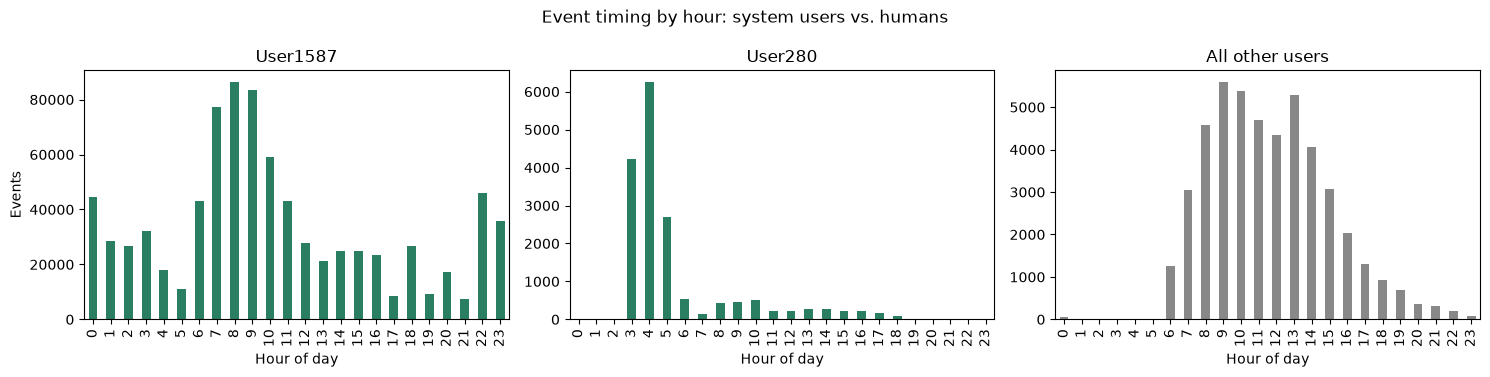

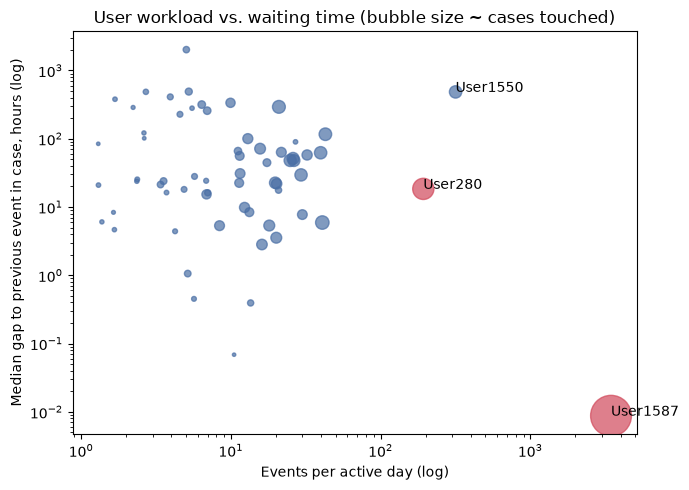

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, u in zip(axes, ["User1587", "User280", "__humans__"]):
    sub = df[~df.User_ID.isin(BOT_USERS)] if u == "__humans__" else df[df.User_ID == u]
    sub.hour.value_counts().reindex(range(24), fill_value=0).plot.bar(ax=ax, color="#2a7f62" if u != "__humans__" else "#888")
    ax.set_title("All other users" if u == "__humans__" else u)
    ax.set_xlabel("Hour of day")
axes[0].set_ylabel("Events")
fig.suptitle("Event timing by hour: system users vs. humans")
fig.tight_layout()
fig.savefig(FIG / "bot_hours.png", dpi=130)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
u = users[users.events >= 20]
ax.scatter(u.events_per_active_day, u.median_gap_s / 3600 + 1e-3, s=np.sqrt(u.cases) * 2,
           c=np.where(u.is_bot, "#d1495b", "#4a6fa5"), alpha=0.7)
for name in BOT_USERS + ["User1550"]:
    ax.annotate(name, (u.loc[name, "events_per_active_day"], u.loc[name, "median_gap_s"] / 3600 + 1e-3))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Events per active day (log)")
ax.set_ylabel("Median gap to previous event in case, hours (log)")
ax.set_title("User workload vs. waiting time (bubble size ~ cases touched)")
fig.tight_layout()
fig.savefig(FIG / "bot_scatter.png", dpi=130)
plt.show()

Cross-check with a simple rule: at least 100 events **and** (more than 150 events per active day **or** more than half of the events between 03:00 and 06:00).

In [6]:
rule = (users.events >= 100) & ((users.events_per_active_day > 150) | (users.batch_0306_share > 0.5))
users.loc[rule, ["events", "active_days", "events_per_active_day", "batch_0306_share", "activities"]].round(2)

,events,active_days,events_per_active_day,batch_0306_share,activities
User_ID,,,,,
User1587,826241,239,3457.08,0.07,8
User280,16962,88,192.75,0.78,2
User1550,1583,5,316.60,0.00,3


## 2b. Case-level KPIs

Per case (`PO_ID`):

- **trace_length** – number of events
- **throughput_days** – first to last event
- **manual_count** – events by non-bot users; **automation_rate** = bot events / all events
- **time_to_post_days** – first event to first posting (when the invoice first became payable; the log has no payment dates)
- `log_*` columns = log(x+1), used in Step 3 because the raw KPIs are strongly right-skewed

In [7]:
df["is_bot"] = df.User_ID.isin(BOT_USERS)
g = df.groupby("PO_ID")
cases = pd.DataFrame({
    "po_type": g.SAP_PO_Type_Code.first(),
    "supplier": g.Supplier_ID.first(),
    "start": g.ts.min(),
    "end": g.ts.max(),
    "trace_length": g.size(),
    "bot_events": g.is_bot.sum(),
    "last_activity": g.Activity_ID.last(),
    "invoice_value_nok": g.Case_Invoice_Value_NOK.first(),
})
cases["throughput_days"] = (cases.end - cases.start).dt.total_seconds() / 86400
posts = df[df.Activity_ID.isin(POSTING_ACTIVITIES)]
cases["first_post"] = posts.groupby("PO_ID").ts.min()
cases["posted"] = cases.first_post.notna()
cases["n_postings"] = posts.groupby("PO_ID").size().reindex(cases.index, fill_value=0)
cases["time_to_post_days"] = (cases.first_post - cases.start).dt.total_seconds() / 86400
cases["manual_count"] = cases.trace_length - cases.bot_events
cases["automation_rate"] = cases.bot_events / cases.trace_length
cases["completed"] = cases.last_activity.isin(POSTING_ACTIVITIES + ["Invoice document deleted"])
for k in ["trace_length", "throughput_days", "manual_count", "time_to_post_days"]:
    cases[f"log_{k}"] = np.log(cases[k] + 1)
cases["start_week"] = cases.start.dt.to_period("W-SUN").dt.start_time
cases.to_csv(OUT / "cases.csv")
print(f"{len(cases):,} cases, {(~cases.completed).sum():,} incomplete, bot share of events {df.is_bot.mean():.1%}")
cases.head()

186,547 cases, 1,779 incomplete, bot share of events 94.7%


,po_type,supplier,start,end,trace_length,bot_events,last_activity,invoice_value_nok,throughput_days,first_post,posted,n_postings,time_to_post_days,manual_count,automation_rate,completed,log_trace_length,log_throughput_days,log_manual_count,log_time_to_post_days,start_week
PO_ID,,,,,,,,,,,,,,,,,,,,,
PurDoc1,NB2,Supplier227,2025-08-21 09:51:33,2025-08-26 10:26:58,3,2,Posted manually,827.76,5.024595,2025-08-26 10:26:58,True,1,5.024595,1,0.666667,True,1.386294,1.795850,0.693147,1.795850,2025-08-18
PurDoc1000,NB2,Supplier135,2025-07-01 17:06:36,2025-07-02 08:14:05,6,4,Posted manually,4467.27,0.630197,2025-07-02 08:14:05,True,1,0.630197,2,0.666667,True,1.945910,0.488701,1.098612,0.488701,2025-06-30
PurDoc100003,NB2,Supplier4,2025-09-17 22:30:32,2025-09-18 04:49:37,3,3,Posted manually,3439.57,0.263252,2025-09-18 04:49:37,True,1,0.263252,0,1.000000,True,1.386294,0.233690,0.000000,0.233690,2025-09-15
PurDoc100005,NB2,Supplier9,2025-08-20 23:36:39,2025-08-22 09:32:41,3,2,Posted manually,314.56,1.413912,2025-08-22 09:32:41,True,1,1.413912,1,0.666667,True,1.386294,0.881249,0.693147,0.881249,2025-08-18
PurDoc100010,NB2,Supplier388,2025-09-10 03:12:35,2025-09-10 12:50:56,5,4,Posted manually,2448.01,0.401632,2025-09-10 12:50:56,True,1,0.401632,1,0.800000,True,1.791759,0.337637,0.693147,0.337637,2025-09-08


KPI summary per PO type (medians, plus the share of touchless cases = no manual activity):

In [8]:
kpi_summary = cases.groupby("po_type").agg(
    cases=("trace_length", "size"),
    median_trace=("trace_length", "median"),
    median_tp_days=("throughput_days", "median"),
    p90_tp_days=("throughput_days", lambda s: s.quantile(0.9)),
    median_manual=("manual_count", "median"),
    mean_automation=("automation_rate", "mean"),
    touchless=("manual_count", lambda s: (s == 0).mean()),
).sort_values("cases", ascending=False)
kpi_summary.round(2)

,cases,median_trace,median_tp_days,p90_tp_days,median_manual,mean_automation,touchless
po_type,,,,,,,
ZNB2,92768,4.0,0.00,0.00,0.0,0.99,0.96
NB2,34669,4.0,1.01,4.98,0.0,0.90,0.66
ZNB4,26349,4.0,0.00,12.86,0.0,0.99,0.93
ZNB3,20336,4.0,0.00,1.12,0.0,0.99,0.95
ZJD1,5519,4.0,2.05,44.23,0.0,0.89,0.60
ZNB1,4753,6.0,9.35,80.41,1.0,0.86,0.47
ZJD3,953,5.0,6.01,80.31,0.0,0.88,0.53
ZNB6,797,4.0,29.10,145.39,1.0,0.75,0.27
ZRPC,364,4.0,4.02,28.08,1.0,0.77,0.26


### Invoice cycles (PO_ID, SAP_PO_No)

Each invoice gets its own SLA clock: from its first event to its first posting.

In [9]:
df["is_post"] = df.Activity_ID.isin(POSTING_ACTIVITIES)
gi = df.groupby(["PO_ID", "SAP_PO_No"])
inv = pd.DataFrame({
    "po_type": gi.SAP_PO_Type_Code.first(),
    "start": gi.ts.min(),
    "first_post": df[df.is_post].groupby(["PO_ID", "SAP_PO_No"]).ts.min(),
    "events": gi.size(),
})
inv["posted"] = inv.first_post.notna()
inv["time_to_post_days"] = (inv.first_post - inv.start).dt.total_seconds() / 86400
inv["log_time_to_post_days"] = np.log(inv.time_to_post_days + 1)
inv["start_week"] = inv.start.dt.to_period("W-SUN").dt.start_time
inv = inv.reset_index()
inv.to_csv(OUT / "invoices.csv", index=False)
print(f"{len(inv):,} invoice cycles, {(cyc > 1).sum():,} cases with more than one")

215,128 invoice cycles, 15,416 cases with more than one


## 1. Workflow per PO type

For each PO type: a frequency DFG (how often one activity follows another) and a performance DFG
(median time between them). For readability, rare activities and edges are filtered out for the big types
(below 0.5% of cases for n ≥ 5,000, below 2% for n ≥ 300).

*(Step 1 is run after the KPIs because the variant table uses throughput time and manual count.)*

In [10]:
log = df.rename(columns={"PO_ID": "case:concept:name", "Activity_ID": "concept:name",
                         "ts": "time:timestamp", "User_ID": "org:resource"})
log = log[["case:concept:name", "concept:name", "time:timestamp", "org:resource", "SAP_PO_Type_Code"]]
cases["variant"] = df.groupby("PO_ID").Activity_ID.agg(" → ".join)

type_rows, variant_rows = [], []
for code, name in PO_TYPES.items():
    sub = log[log.SAP_PO_Type_Code == code]
    c = cases[cases.po_type == code]
    n = len(c)

    min_share = 0.005 if n >= 5000 else 0.02 if n >= 300 else 0.0
    dfg, sa, ea = pm4py.discover_dfg(sub)
    act_cases = sub.groupby("concept:name")["case:concept:name"].nunique()
    keep = set(act_cases[act_cases >= min_share * n].index)
    dfg = {k: v for k, v in dfg.items() if k[0] in keep and k[1] in keep and v >= min_share * n}
    # pm4py can only draw start/end arcs to activities that still appear on an edge
    on_edge = {a for e in dfg for a in e}
    sa = {k: v for k, v in sa.items() if k in on_edge}
    ea = {k: v for k, v in ea.items() if k in on_edge}
    pm4py.save_vis_dfg(dfg, sa, ea, str(FIG / "process_maps" / f"dfg_freq_{code}.png"))

    perf, _, _ = pm4py.discover_performance_dfg(sub)
    perf = {k: v for k, v in perf.items() if k in dfg}
    pm4py.save_vis_performance_dfg(perf, sa, ea, str(FIG / "process_maps" / f"dfg_perf_{code}.png"),
                                   aggregation_measure="median")

    vc = c.groupby("variant").agg(cases=("variant", "size"),
                                  median_tp_days=("throughput_days", "median"),
                                  mean_manual=("manual_count", "mean"))
    vc = vc.sort_values("cases", ascending=False)
    vc["share"] = vc.cases / n
    vc["cum_share"] = vc.share.cumsum()
    for rank, (v, r) in enumerate(vc.head(10).iterrows(), 1):
        variant_rows.append({"po_type": code, "rank": rank, "variant": v, **r.to_dict()})

    type_rows.append({
        "po_type": code, "name": name, "cases": n, "events": len(sub),
        "activities": sub["concept:name"].nunique(), "variants": len(vc),
        "top1_share": vc.share.iloc[0], "top5_share": vc.share.head(5).sum(),
        "variants_for_80pct": int((vc.cum_share < 0.8).sum() + 1),
        "map_filter": f">= {min_share:.1%} of cases" if min_share else "none",
    })

types = pd.DataFrame(type_rows).set_index("po_type")
types.to_csv(OUT / "po_type_overview.csv")
top_variants = pd.DataFrame(variant_rows)
top_variants.to_csv(OUT / "top_variants.csv", index=False)
types.round(3)

,name,cases,events,activities,variants,top1_share,top5_share,variants_for_80pct,map_filter
po_type,,,,,,,,,
NB2,Return to vendor,34669,171223,24,302,0.349,0.880,4,>= 0.5% of cases
ZJD1,Normal order,5519,40241,21,838,0.464,0.681,29,>= 0.5% of cases
ZJD3,Automatic order,953,10788,20,289,0.367,0.580,99,>= 2.0% of cases
ZNB1,Manual order,4753,50963,22,1161,0.296,0.515,211,>= 2.0% of cases
ZNB2,Third-party order Type 1,92768,387113,19,169,0.951,0.984,1,>= 0.5% of cases
ZNB3,Third-party order Type 2,20336,87549,16,60,0.675,0.982,2,>= 0.5% of cases
ZNB4,Third-party order Type 3,26349,135226,22,152,0.735,0.916,2,>= 0.5% of cases
ZNB6,Third-party order Type 4,797,5493,21,149,0.266,0.696,16,>= 2.0% of cases
ZNBF,Transportation order,34,271,11,10,0.706,0.853,4,none


Process maps. Change `SHOW` to look at other PO types (all maps are saved in `ap_output/figures/process_maps/`).

ZNB1 – Manual order: frequency map, then performance map (median time)


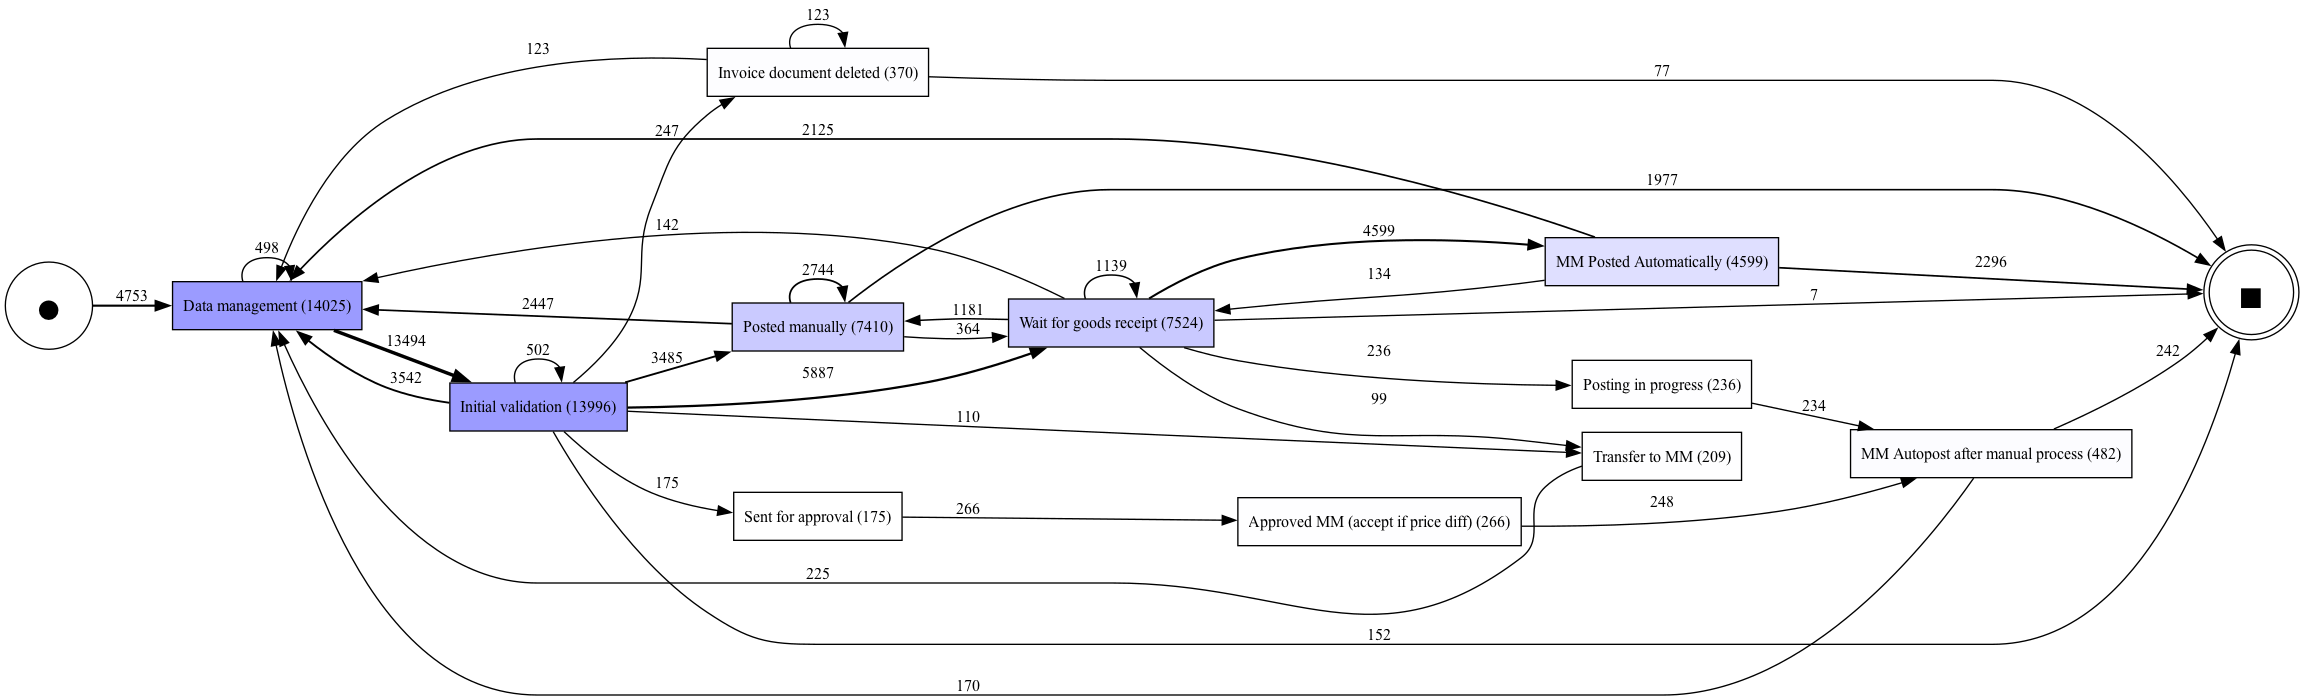

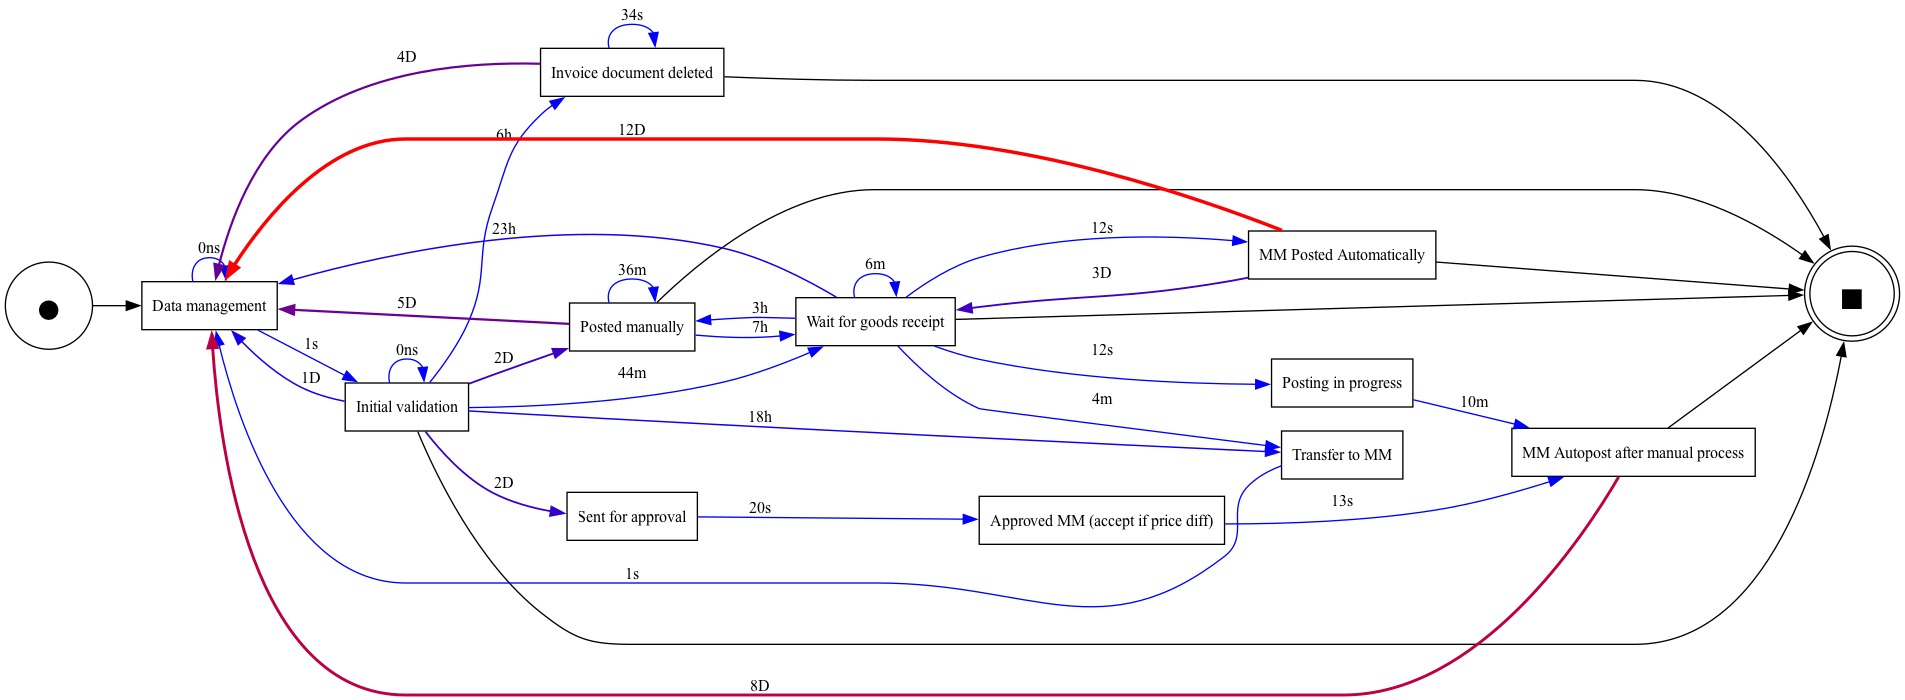

ZJD1 – Normal order: frequency map, then performance map (median time)


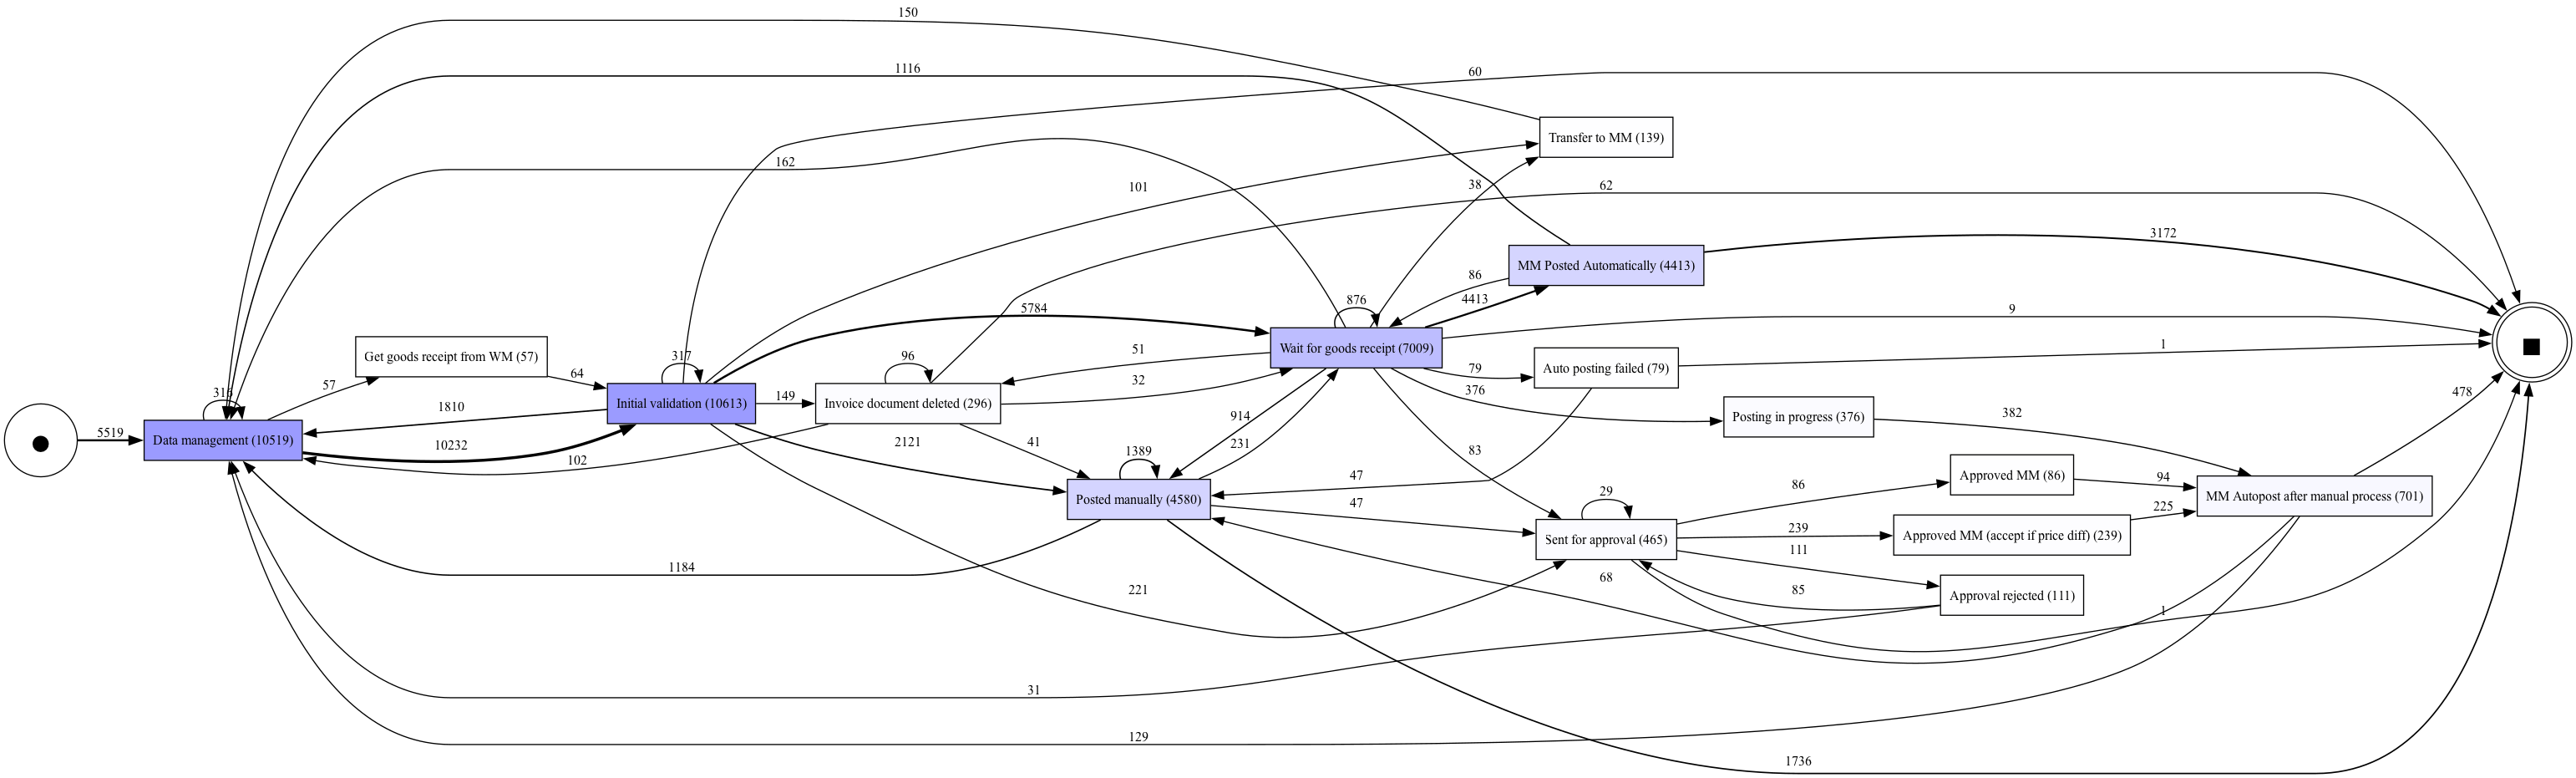

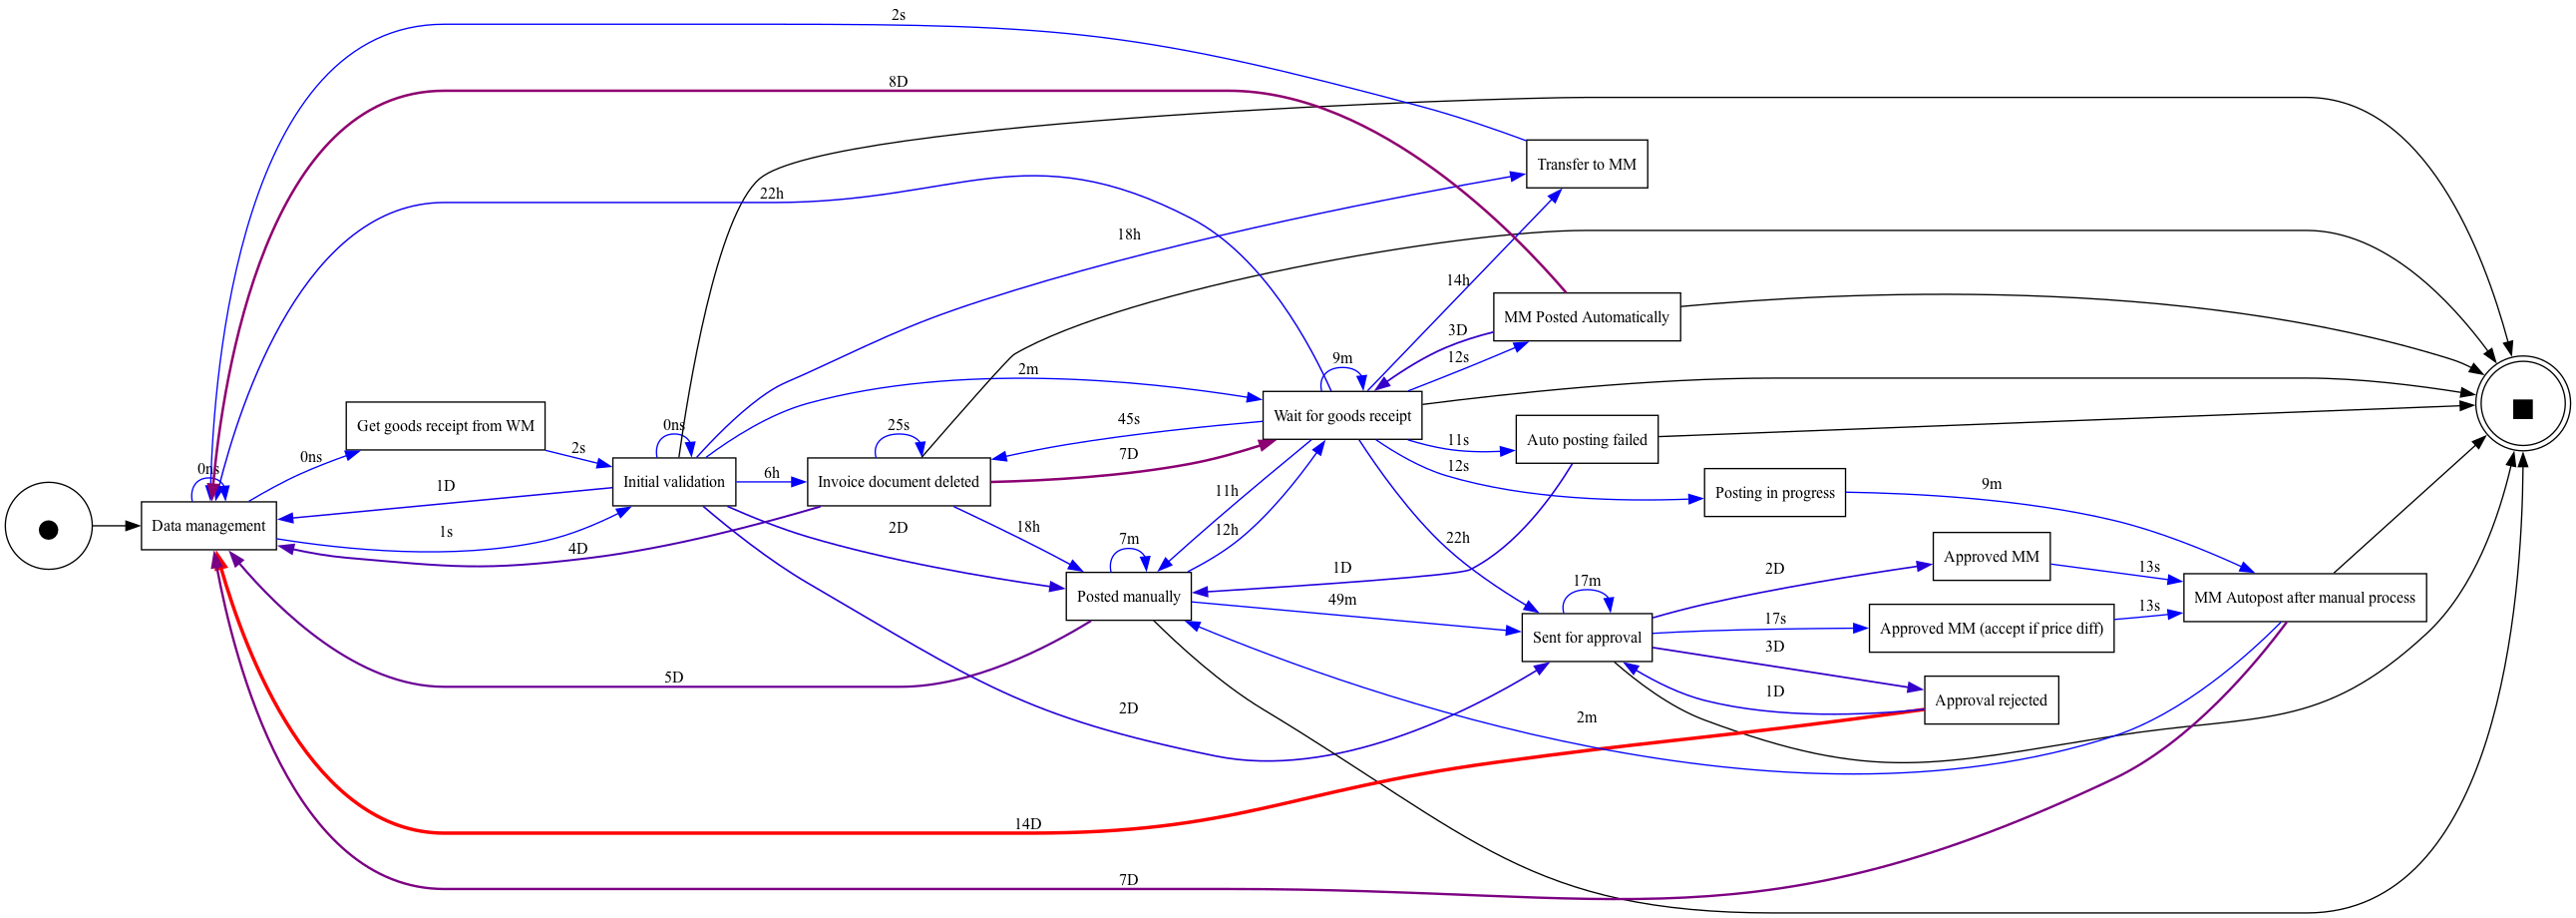

NB2 – Return to vendor: frequency map, then performance map (median time)


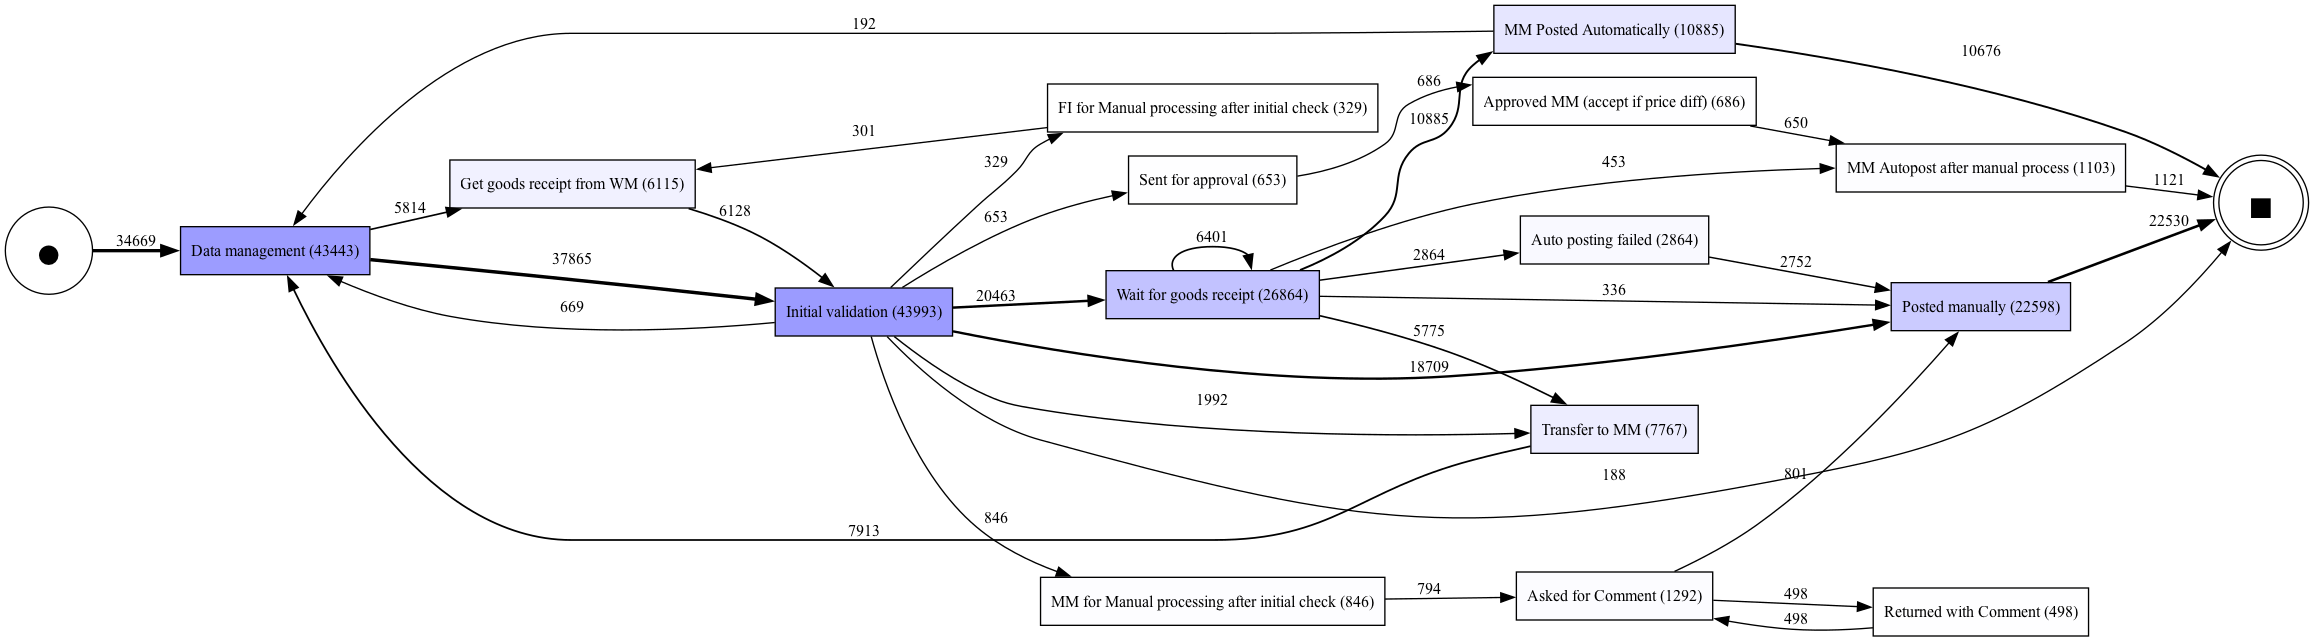

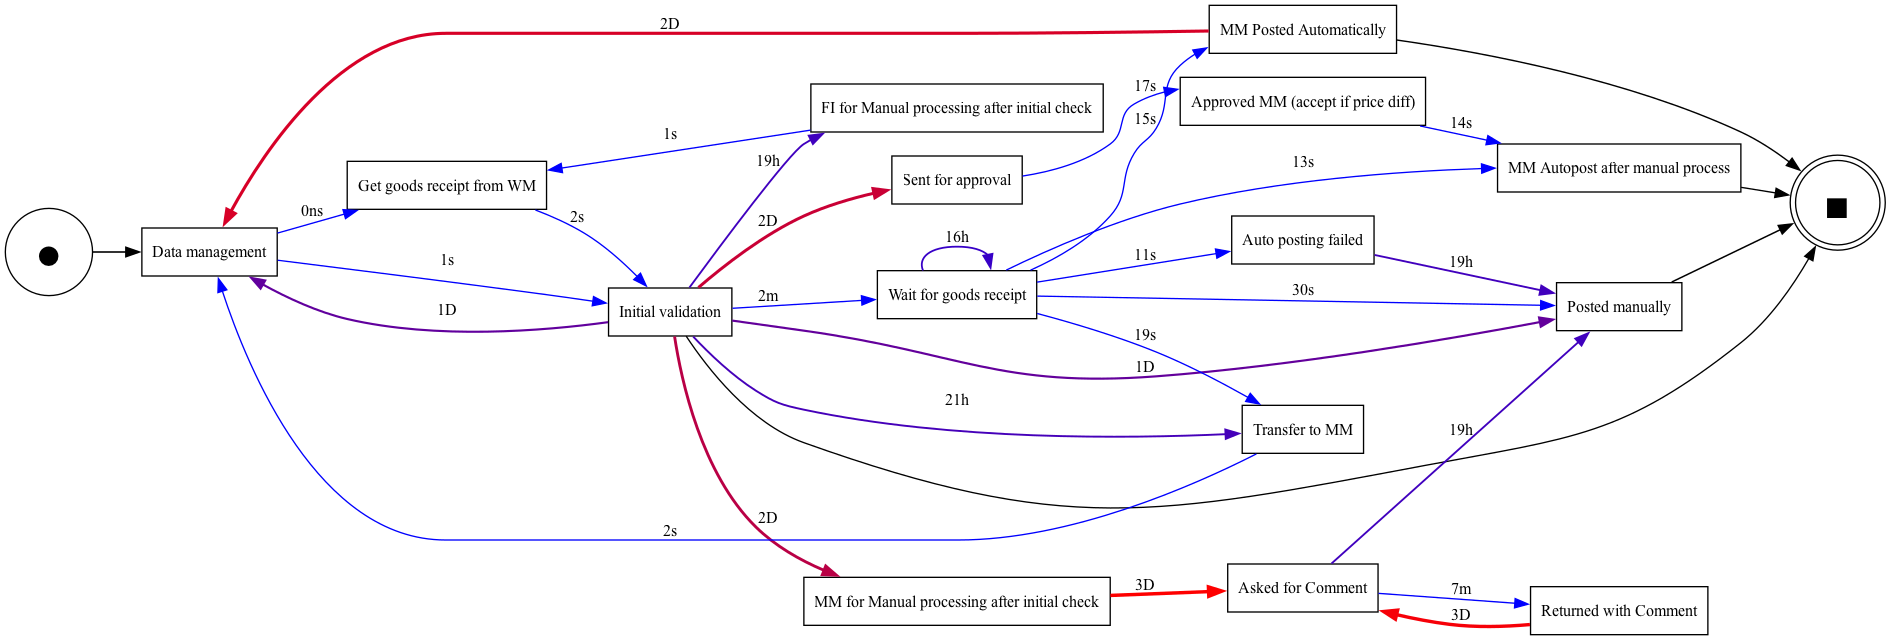

In [11]:
SHOW = ["ZNB1", "ZJD1", "NB2"]
for code in SHOW:
    print(f"{code} – {PO_TYPES[code]}: frequency map, then performance map (median time)")
    display(Image(str(FIG / "process_maps" / f"dfg_freq_{code}.png"), width=900))
    display(Image(str(FIG / "process_maps" / f"dfg_perf_{code}.png"), width=900))

Top 3 variants per PO type:

In [12]:
with pd.option_context("display.max_colwidth", 140):
    display(top_variants[top_variants["rank"] <= 3][["po_type", "rank", "cases", "share", "median_tp_days", "variant"]].round(3))

,po_type,rank,cases,share,median_tp_days,variant
0,NB2,1,12110.0,0.349,1.521,Data management → Initial validation → Posted manually
1,NB2,2,10437.0,0.301,0.002,Data management → Initial validation → Wait for goods receipt → MM Posted Automatically
2,NB2,3,3932.0,0.113,1.890,Data management → Get goods receipt from WM → Initial validation → Wait for goods receipt → Wait for goods receipt → Transfer to MM → Da...
10,ZJD1,1,2559.0,0.464,0.002,Data management → Initial validation → Wait for goods receipt → MM Posted Automatically
11,ZJD1,2,565.0,0.102,3.176,Data management → Initial validation → Posted manually
12,ZJD1,3,253.0,0.046,11.771,Data management → Initial validation → Wait for goods receipt → MM Posted Automatically → Data management → Initial validation → Wait fo...
20,ZJD3,1,350.0,0.367,1.004,Data management → Initial validation → Wait for goods receipt → MM Posted Automatically
21,ZJD3,2,81.0,0.085,3.043,Data management → Initial validation → Posted manually
22,ZJD3,3,60.0,0.063,22.004,Data management → Initial validation → Wait for goods receipt → MM Posted Automatically → Data management → Initial validation → Wait fo...
30,ZNB1,1,1408.0,0.296,0.002,Data management → Initial validation → Wait for goods receipt → MM Posted Automatically


Which activities occur in which PO type (share of cases containing the activity):

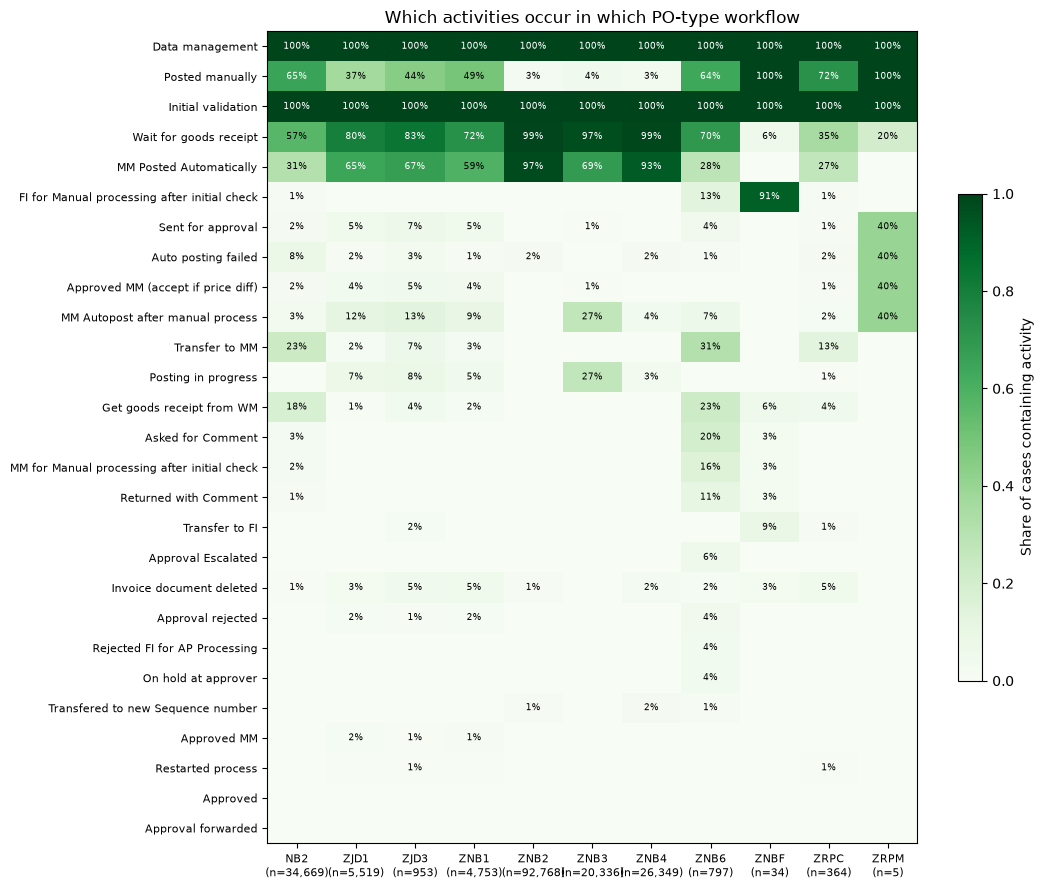

In [13]:
pres = (df.drop_duplicates(["PO_ID", "Activity_ID"])
          .groupby(["SAP_PO_Type_Code", "Activity_ID"]).PO_ID.nunique()
          .unstack(0).reindex(columns=list(PO_TYPES)))
pres = pres.div(types.cases, axis=1).fillna(0)
pres = pres.loc[pres.max(axis=1).sort_values(ascending=False).index]
pres.to_csv(OUT / "activity_presence.csv")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(pres.values, cmap="Greens", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(pres.columns)), [f"{c}\n(n={types.cases[c]:,})" for c in pres.columns], fontsize=8)
ax.set_yticks(range(len(pres.index)), pres.index, fontsize=8)
for i in range(pres.shape[0]):
    for j in range(pres.shape[1]):
        v = pres.values[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=6.5, color="white" if v > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Share of cases containing activity", shrink=0.6)
ax.set_title("Which activities occur in which PO-type workflow")
fig.tight_layout()
fig.savefig(FIG / "activity_presence.png", dpi=130)
plt.show()

## 3a. Control charts

All KPIs are charted on the log(x+1) scale.

- **X̄–S charts** with weekly subgroups (week the case started) for PO types with at least 5 cases per week on average.
  Subgroup sizes vary, so each week gets its own limits; sigma = pooled within-week standard deviation.
- **I-MR charts** on individual cases for the very small types.
- Robustness check: the weekly means charted as individuals (treats normal week-to-week variation as common cause).

Western Electric rules on the standardised values z:
R1 one point beyond 3σ · R2 2 of 3 beyond 2σ (same side) · R3 4 of 5 beyond 1σ (same side) ·
R4 8 in a row on one side · R5 6 in a row steadily increasing or decreasing.

In [14]:
MIN_CASES_PER_WEEK = 5      # mean cases/week needed for an X̄–S chart
MIN_SUBGROUP = 2            # weeks with fewer cases are left out of X̄–S charts
RULES = ["R1", "R2", "R3", "R4", "R5"]


def c4(n):
    n = np.asarray(n, dtype=float)
    return np.sqrt(2 / (n - 1)) * np.exp(gammaln(n / 2) - gammaln((n - 1) / 2))


def shewhart_rules(z):
    """Return dict rule -> boolean array marking the points that trigger it."""
    z = np.asarray(z, dtype=float)
    n = len(z)
    hits = {r: np.zeros(n, bool) for r in RULES}
    hits["R1"] = np.abs(z) > 3
    for i in range(n):
        for side in (1, -1):
            s = side * z
            if i >= 2 and (s[i - 2:i + 1] > 2).sum() >= 2:
                hits["R2"][i - 2:i + 1] |= s[i - 2:i + 1] > 2
            if i >= 4 and (s[i - 4:i + 1] > 1).sum() >= 4:
                hits["R3"][i - 4:i + 1] |= s[i - 4:i + 1] > 1
            if i >= 7 and (s[i - 7:i + 1] > 0).all():
                hits["R4"][i - 7:i + 1] = True
        if i >= 5:
            d = np.diff(z[i - 5:i + 1])
            if (d > 0).all() or (d < 0).all():
                hits["R5"][i - 5:i + 1] = True
    return hits


def draw(ax, x, y, center, lcl, ucl, hits, title, ylabel):
    ax.plot(x, y, "-", color="#4a6fa5", lw=1, marker="o", ms=3, zorder=2)
    ax.plot(x, np.broadcast_to(center, len(x)), color="#2a7f62", lw=1)
    ax.step(x, np.broadcast_to(ucl, len(x)), where="mid", color="#d1495b", lw=1, ls="--")
    ax.step(x, np.broadcast_to(lcl, len(x)), where="mid", color="#d1495b", lw=1, ls="--")
    bad = np.zeros(len(x), bool)
    for r in hits.values():
        bad |= r
    ax.scatter(np.asarray(x)[bad], np.asarray(y)[bad], color="#d1495b", s=18, zorder=3)
    ax.set_title(title, fontsize=9)
    ax.set_ylabel(ylabel, fontsize=8)
    ax.tick_params(labelsize=7)
    if isinstance(x, pd.DatetimeIndex):
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
        ax.tick_params(axis="x", rotation=45)

Red points break at least one rule. Each figure: left = X̄ (or individuals) chart, right = S (or moving-range) chart.

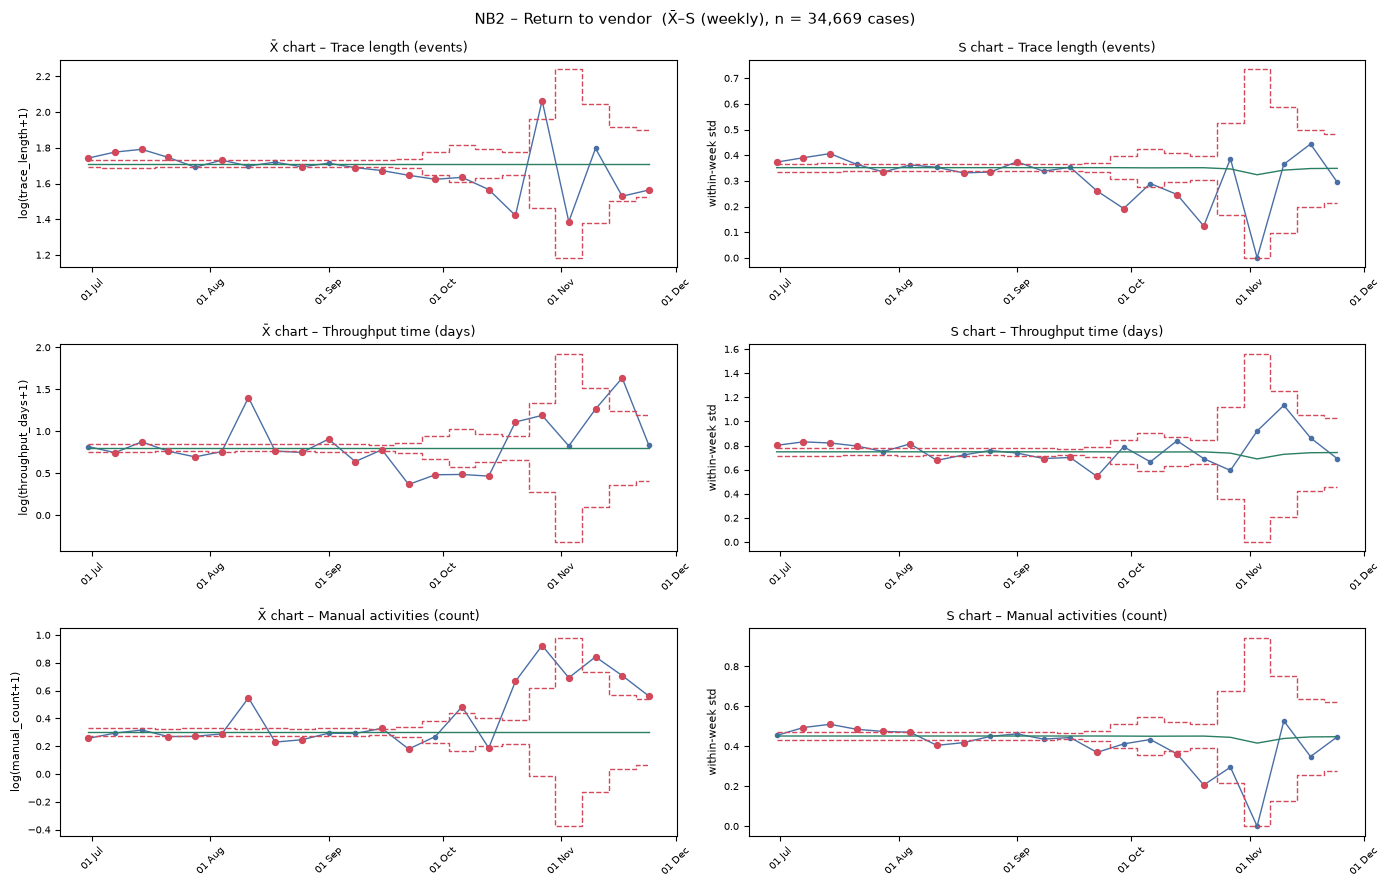

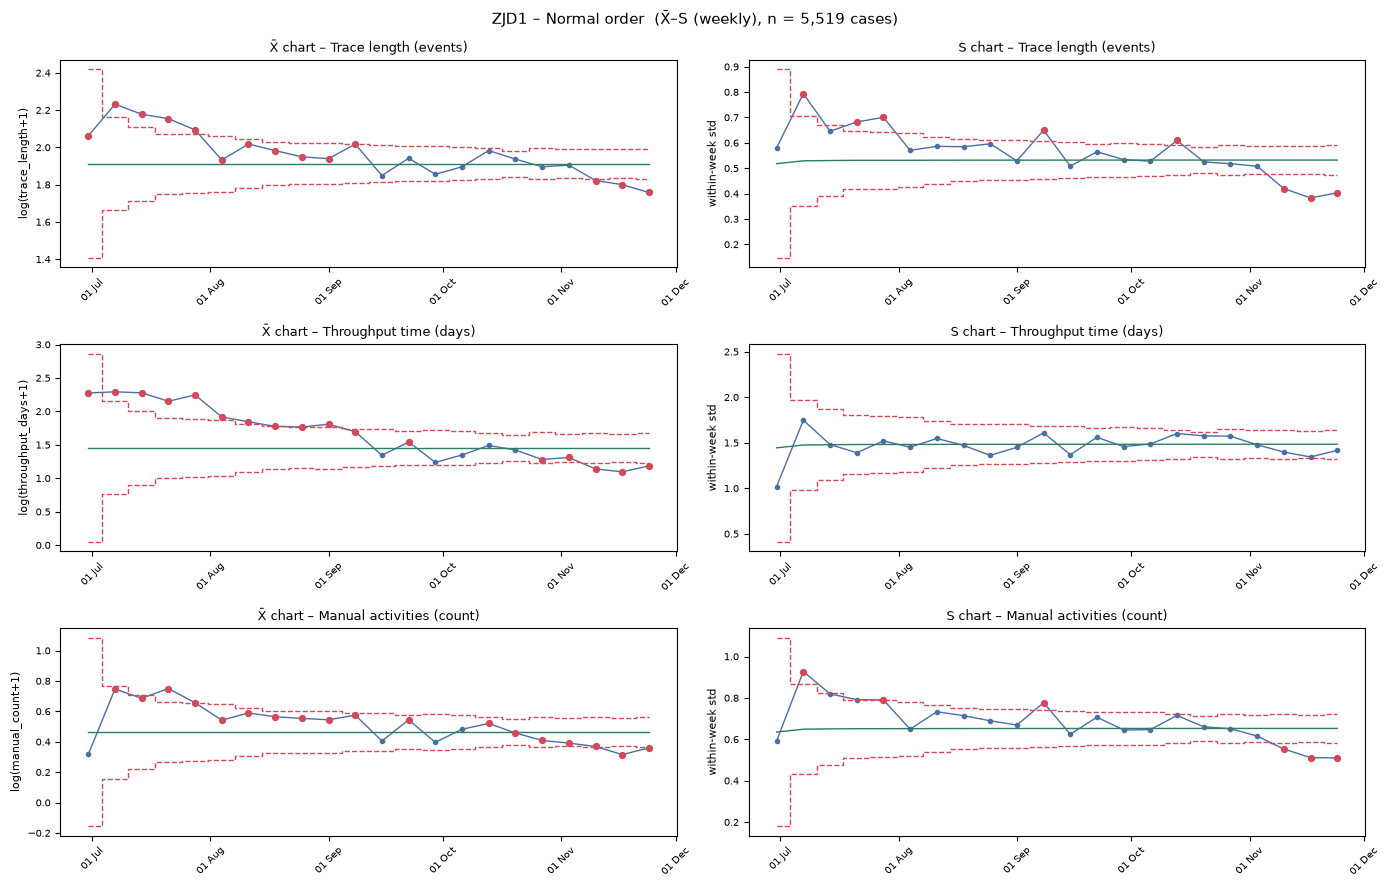

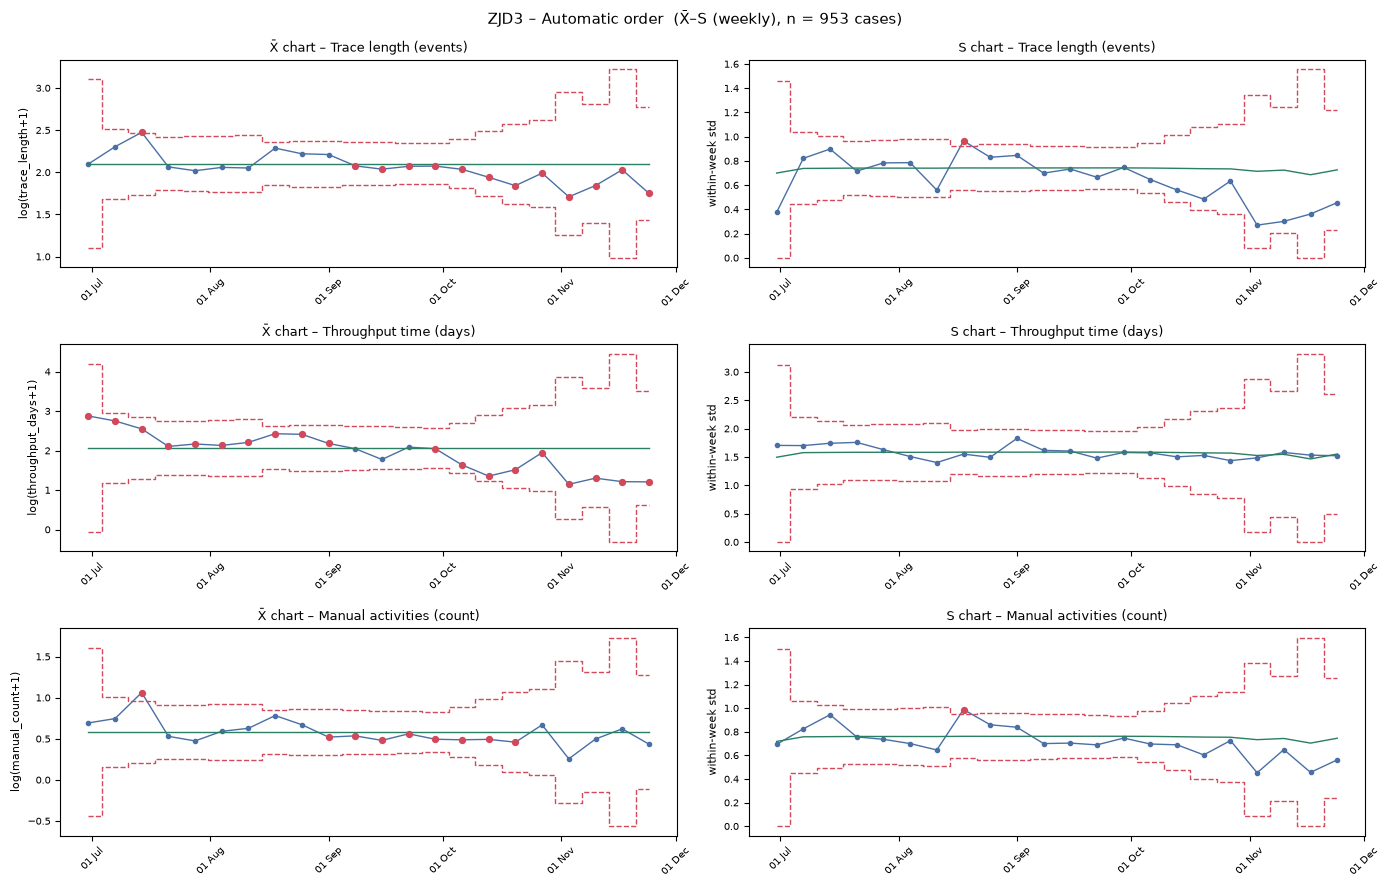

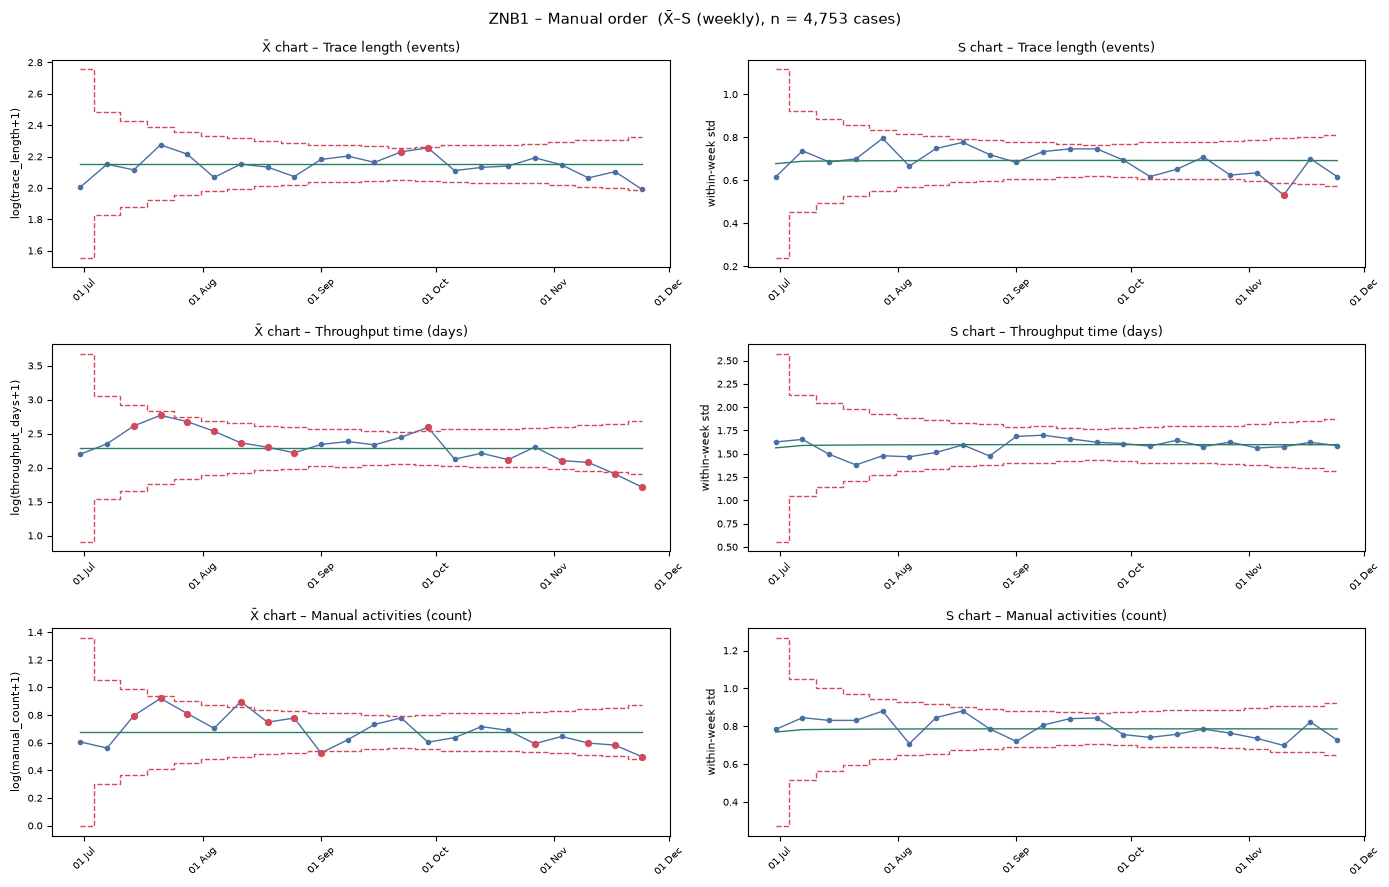

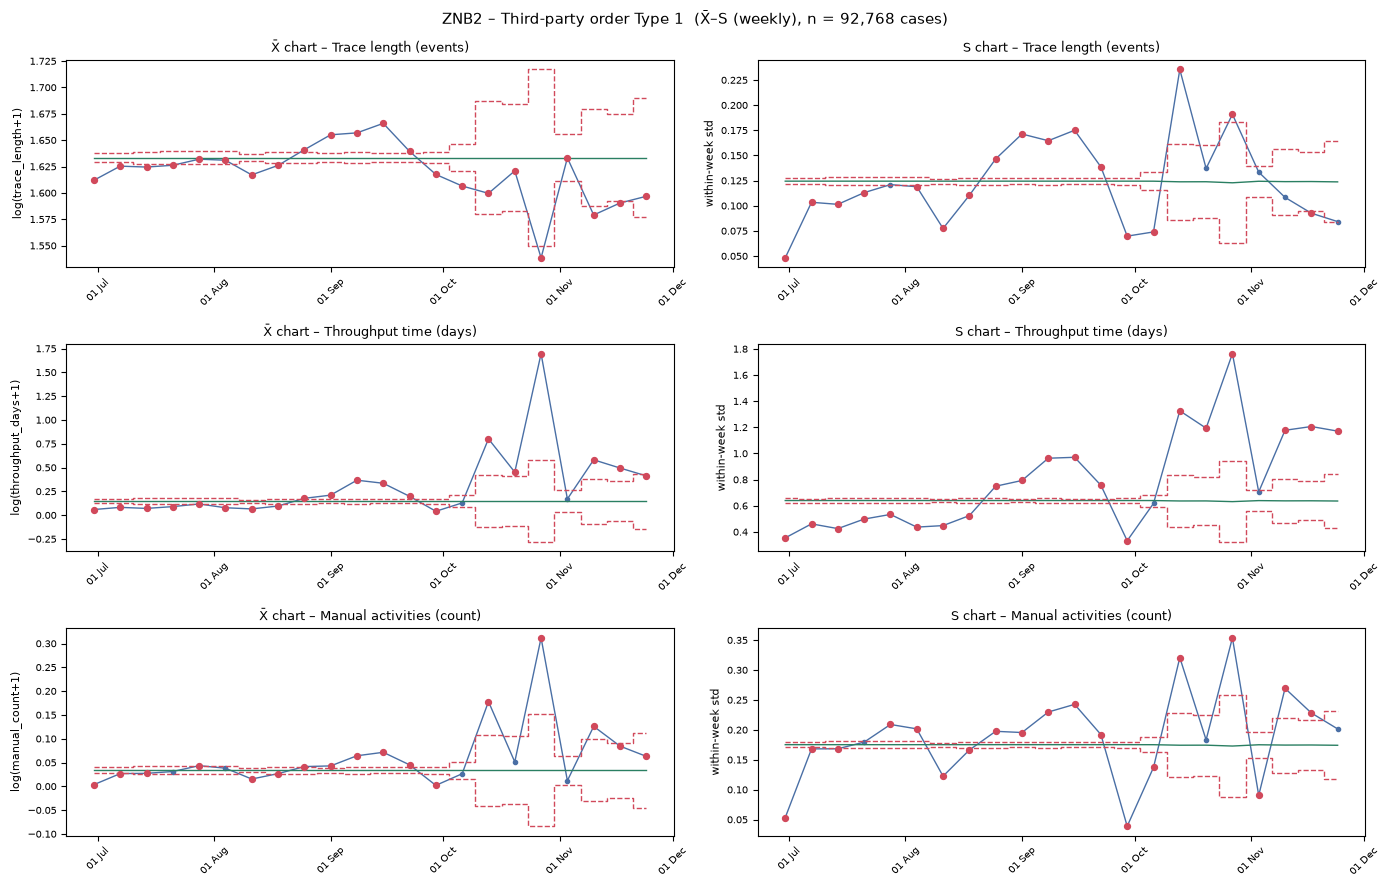

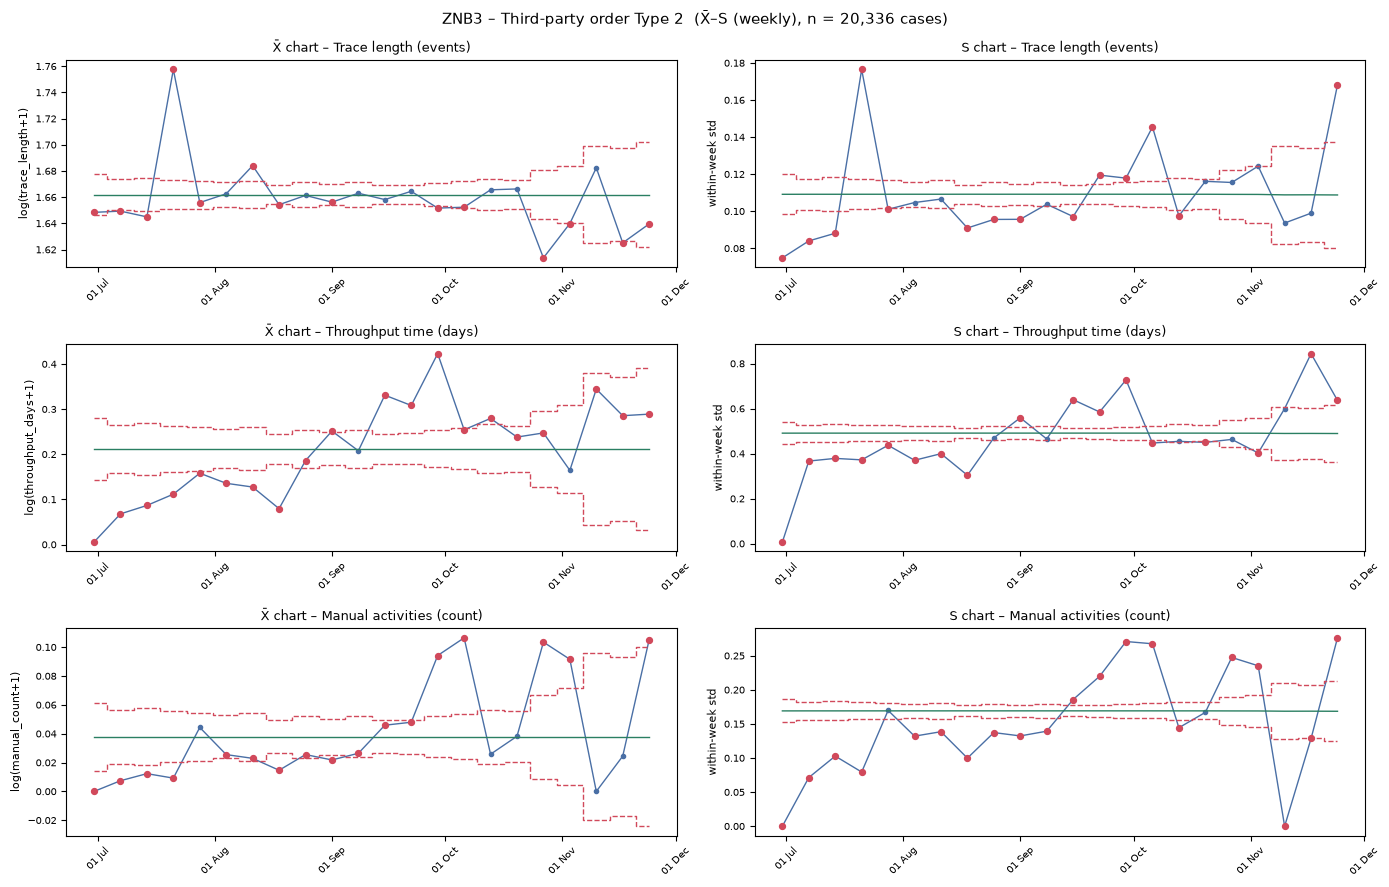

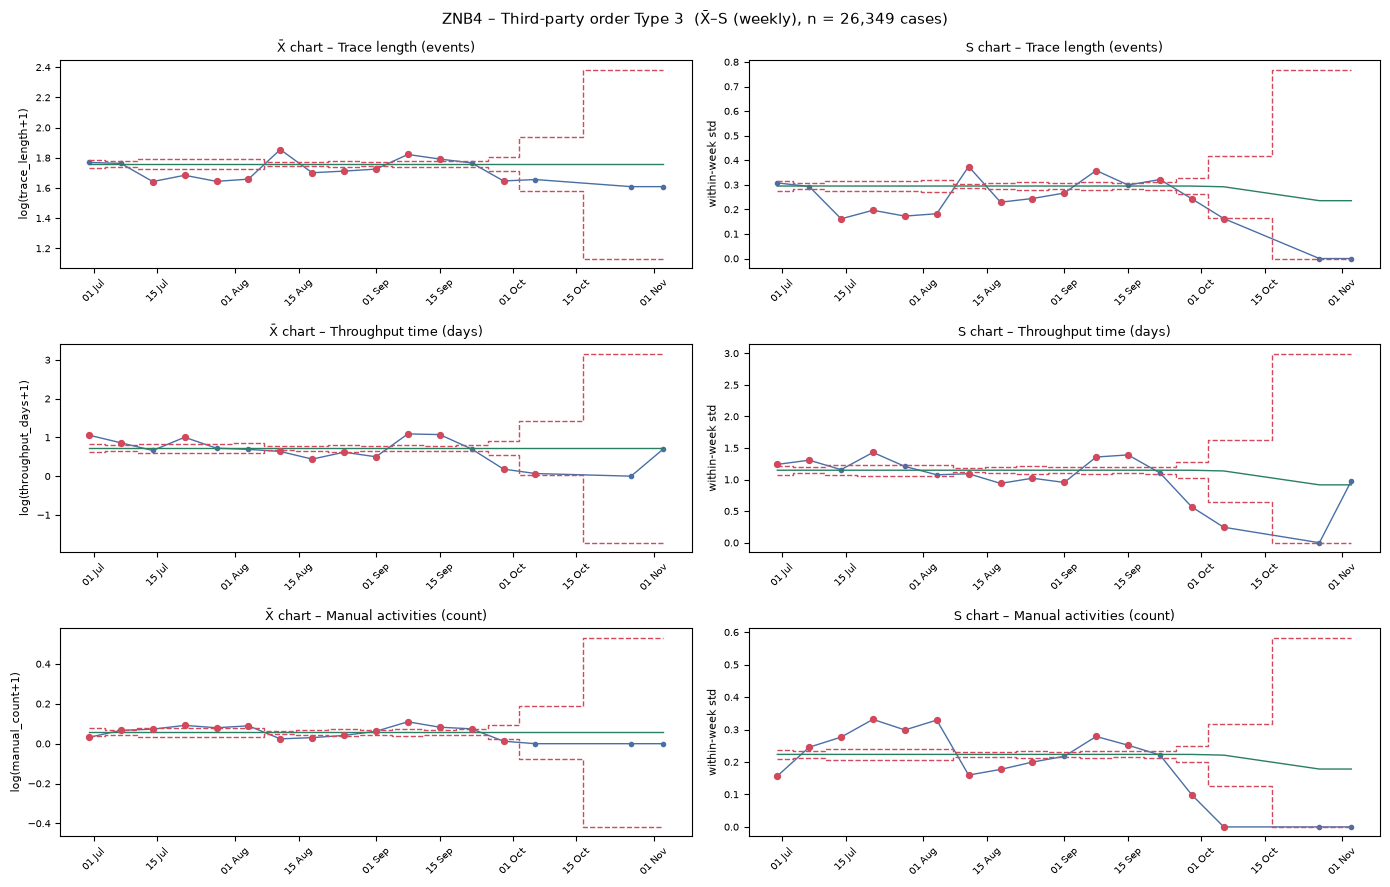

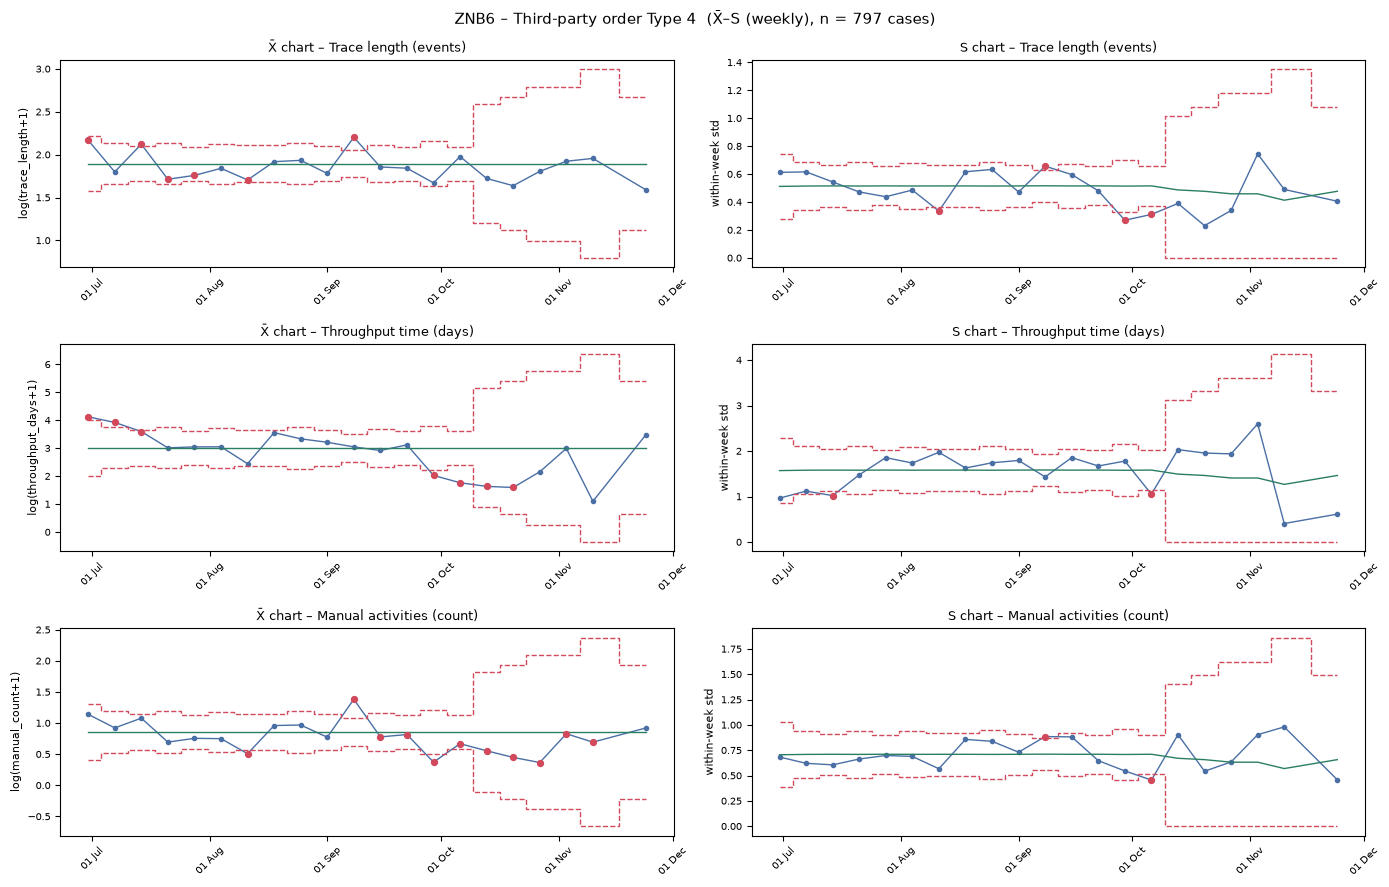

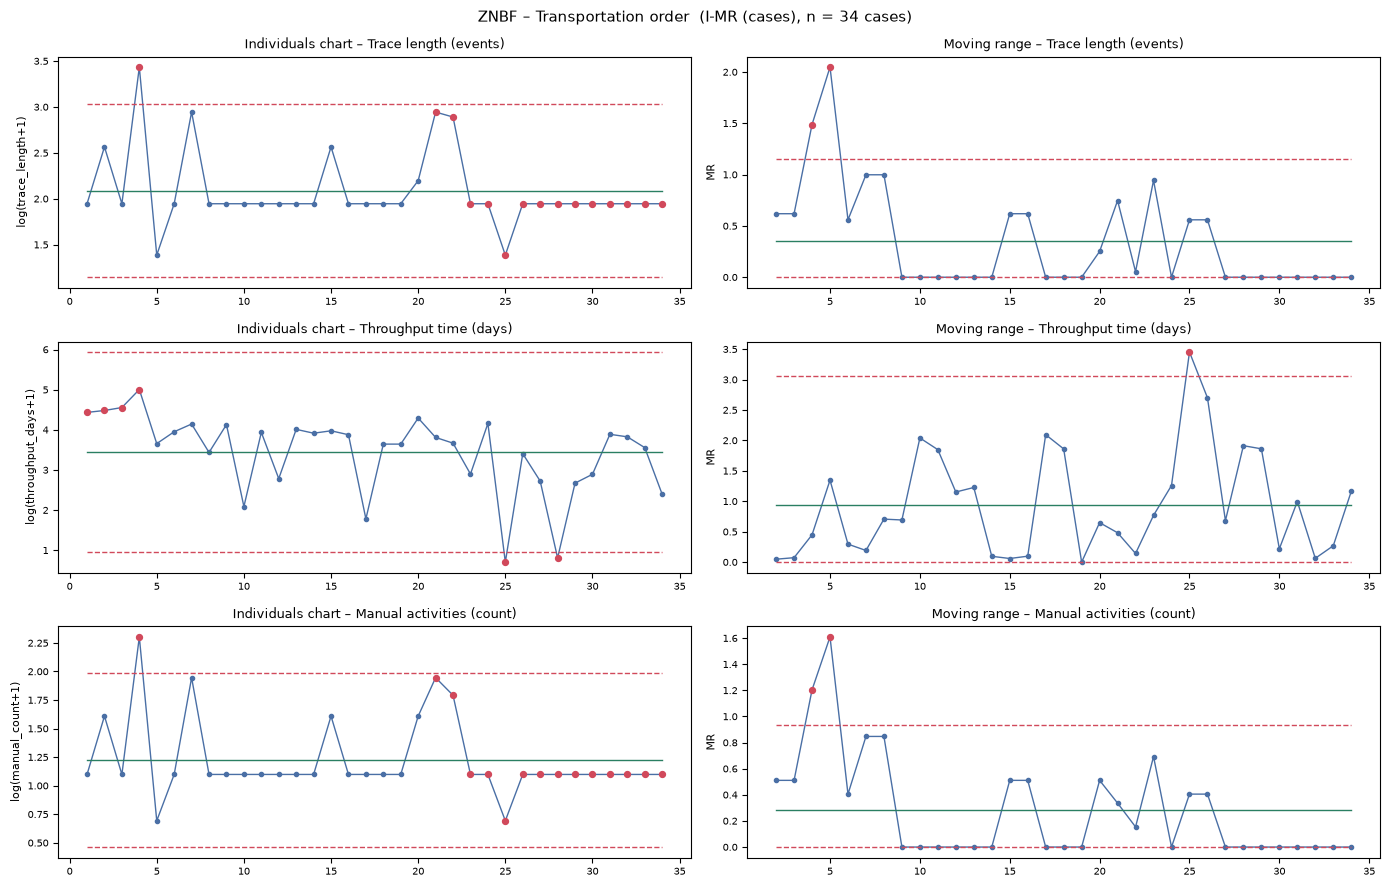

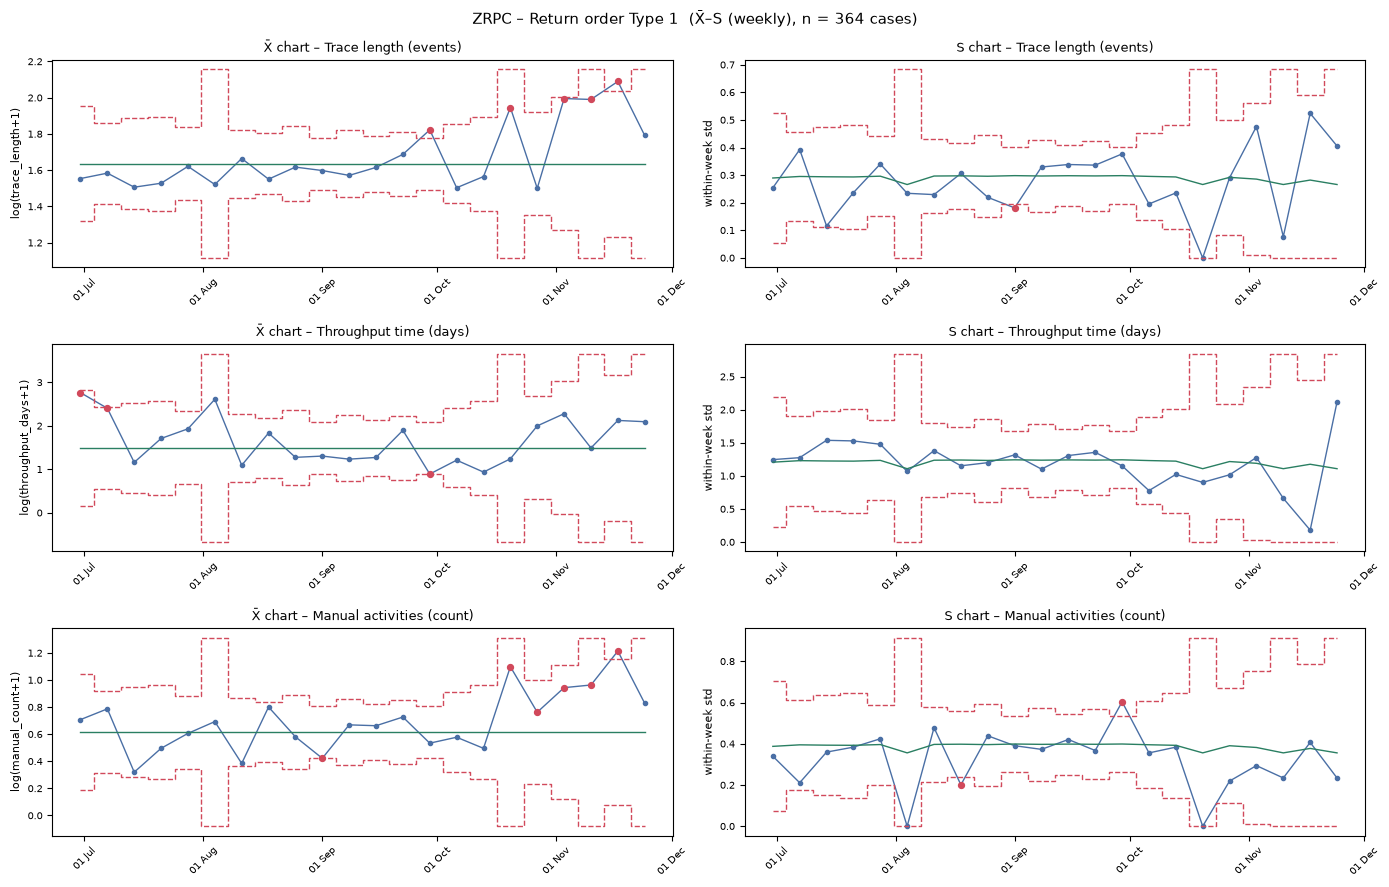

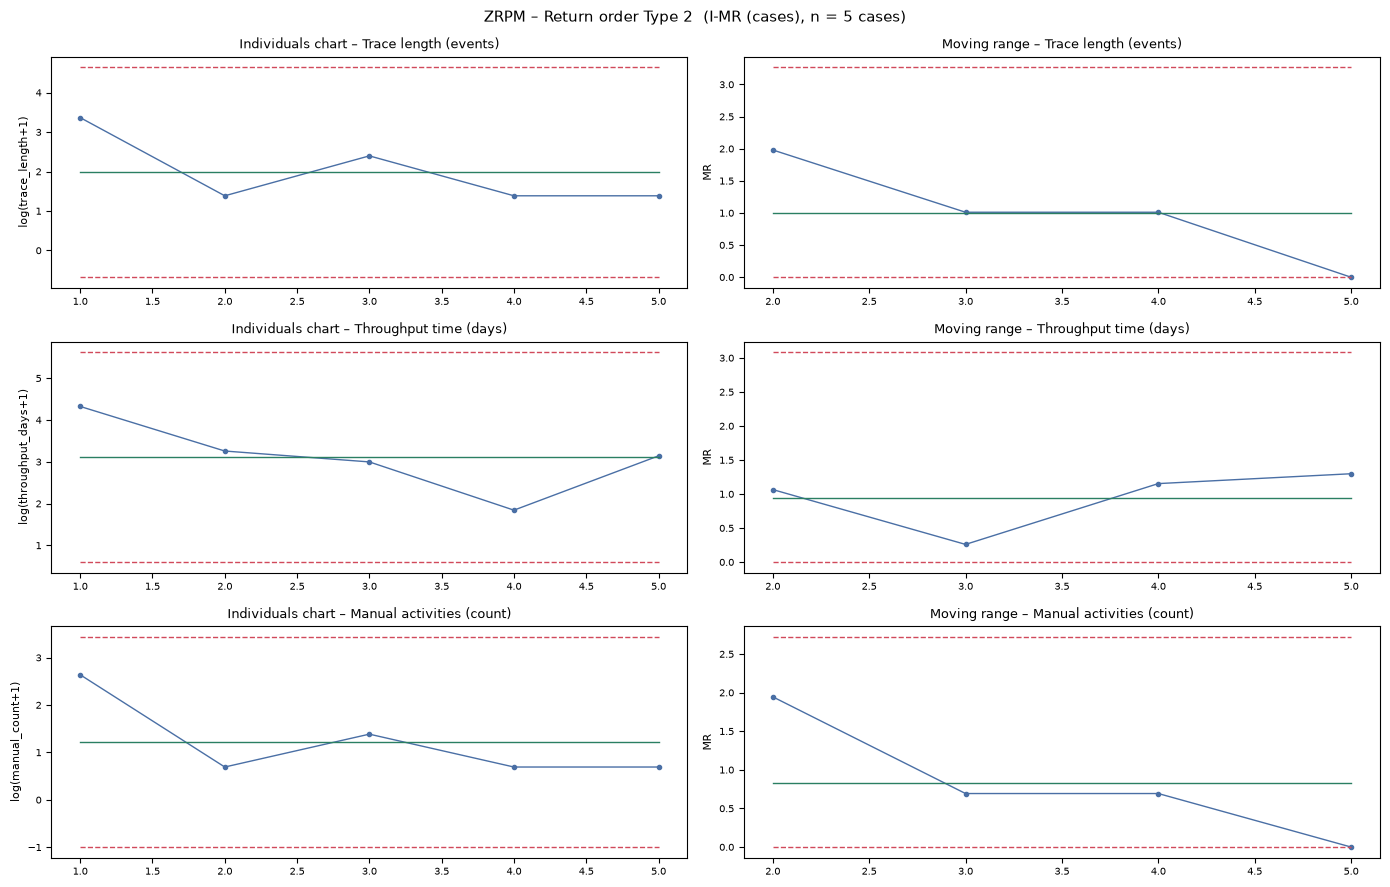

In [15]:
rows = []
for code, name in PO_TYPES.items():
    c = cases[cases.po_type == code].sort_values("start")
    weeks = c.groupby("start_week")
    use_xbar = len(c) / max(weeks.ngroups, 1) >= MIN_CASES_PER_WEEK
    chart_type = "X̄–S (weekly)" if use_xbar else "I-MR (cases)"

    fig, axes = plt.subplots(len(KPIS), 2, figsize=(14, 3.0 * len(KPIS)), squeeze=False)
    for k_i, (kpi, label) in enumerate(KPIS.items()):
        col = f"log_{kpi}"
        row = {"po_type": code, "kpi": kpi, "chart": chart_type, "cases": len(c)}
        if use_xbar:
            agg = weeks[col].agg(["mean", "std", "size"])
            agg = agg[agg["size"] >= MIN_SUBGROUP]
            n = agg["size"].values
            xbarbar = np.average(agg["mean"], weights=n)
            sigma = np.sqrt(((n - 1) * agg["std"] ** 2).sum() / (n - 1).sum())  # pooled within-week
            se = sigma / np.sqrt(n)
            hits = shewhart_rules((agg["mean"].values - xbarbar) / se)
            draw(axes[k_i, 0], agg.index, agg["mean"], xbarbar, xbarbar - 3 * se, xbarbar + 3 * se, hits,
                 f"X̄ chart – {label}", f"log({kpi}+1)")
            s_c = sigma * c4(n)
            s_w = sigma * np.sqrt(1 - c4(n) ** 2)
            s_hits = {"R1": (agg["std"].values > s_c + 3 * s_w) | (agg["std"].values < np.maximum(s_c - 3 * s_w, 0))}
            draw(axes[k_i, 1], agg.index, agg["std"], s_c, np.maximum(s_c - 3 * s_w, 0), s_c + 3 * s_w, s_hits,
                 f"S chart – {label}", "within-week std")

            # robustness: weekly means as individuals
            mr = np.abs(np.diff(agg["mean"].values))
            hits_w = shewhart_rules((agg["mean"].values - agg["mean"].mean()) / (mr.mean() / 1.128))
            row.update({"subgroups": len(agg), "sigma_within": sigma,
                        "s_chart_R1": int(s_hits["R1"].sum()),
                        "weekly_I_violations": int(np.any(np.vstack(list(hits_w.values())), axis=0).sum()),
                        "weekly_I_in_control": not any(h.any() for h in hits_w.values())})
        else:
            y = c[col].values
            mr = np.abs(np.diff(y))
            sigma = mr.mean() / 1.128 if len(mr) else np.nan
            center = y.mean()
            z = (y - center) / sigma if sigma and sigma > 0 else np.zeros_like(y)
            hits = shewhart_rules(z)
            x = np.arange(1, len(y) + 1)
            draw(axes[k_i, 0], x, y, center, center - 3 * sigma, center + 3 * sigma, hits,
                 f"Individuals chart – {label}", f"log({kpi}+1)")
            mr_hits = {"R1": mr > 3.267 * mr.mean()} if len(mr) else {"R1": np.array([], bool)}
            draw(axes[k_i, 1], x[1:], mr, mr.mean(), 0, 3.267 * mr.mean(), mr_hits,
                 f"Moving range – {label}", "MR")
            row.update({"subgroups": len(y), "sigma_within": sigma, "s_chart_R1": int(mr_hits["R1"].sum()),
                        "weekly_I_violations": np.nan, "weekly_I_in_control": np.nan})
        row.update({r: int(h.sum()) for r, h in hits.items()})
        row["points_flagged"] = int(np.any(np.vstack(list(hits.values())), axis=0).sum())
        row["in_control"] = row["points_flagged"] == 0 and row["s_chart_R1"] == 0
        rows.append(row)
    fig.suptitle(f"{code} – {name}  ({chart_type}, n = {len(c):,} cases)", fontsize=11)
    fig.tight_layout()
    fig.savefig(FIG / "control_charts" / f"cc_{code}.png", dpi=110)
    plt.show()

control = pd.DataFrame(rows)
control.to_csv(OUT / "control_chart_results.csv", index=False)

Summary: number of points breaking each rule, and the verdicts (strict X̄–S and weekly-means robustness check).

In [16]:
control[["po_type", "kpi", "chart", "subgroups", *RULES, "s_chart_R1", "in_control", "weekly_I_in_control"]]

,po_type,kpi,chart,subgroups,R1,R2,R3,R4,R5,s_chart_R1,in_control,weekly_I_in_control
0,NB2,trace_length,X̄–S (weekly),22,11,15,14,0,0,11,False,False
1,NB2,throughput_days,X̄–S (weekly),22,14,13,16,0,0,9,False,False
2,NB2,manual_count,X̄–S (weekly),22,15,10,12,0,0,10,False,False
3,ZJD1,trace_length,X̄–S (weekly),22,8,8,6,11,0,8,False,False
4,ZJD1,throughput_days,X̄–S (weekly),22,11,15,17,11,0,0,False,False
5,ZJD1,manual_count,X̄–S (weekly),22,4,12,16,10,6,6,False,False
6,ZJD3,trace_length,X̄–S (weekly),22,1,0,4,12,0,1,False,False
7,ZJD3,throughput_days,X̄–S (weekly),22,0,2,7,19,0,0,False,False
8,ZJD3,manual_count,X̄–S (weekly),22,1,0,0,8,0,1,False,False
9,ZNB1,trace_length,X̄–S (weekly),22,0,2,0,0,0,1,False,True


## 3b. Process capability

Upper-limit capability on the log scale: **Cpu = (log(USL+1) − μ) / (3 σ_within)**, with USL = 10 days (soft) and 30 days (hard).
Cpu ≥ 1 means the process (if stable and roughly normal on the log scale) stays below the SLA almost always.
**Ppu** uses the overall σ instead; the observed breach rates are shown next to it as a reality check.

In [17]:
cap_rows = []
for code, name in PO_TYPES.items():
    c = cases[cases.po_type == code]
    y = c.log_throughput_days
    mu, s_overall = y.mean(), y.std(ddof=1)
    s_within = control.loc[(control.po_type == code) & (control.kpi == "throughput_days"), "sigma_within"].iloc[0]
    r = {"po_type": code, "name": name, "cases": len(c), "mean_log_tp": mu,
         "sigma_within": s_within, "sigma_overall": s_overall,
         "median_tp_days": c.throughput_days.median(), "p90_tp_days": c.throughput_days.quantile(0.9)}
    for tag, usl_days in (("soft10", SLA_SOFT_DAYS), ("hard30", SLA_HARD_DAYS)):
        usl = np.log(usl_days + 1)
        r[f"Cpu_{tag}"] = (usl - mu) / (3 * s_within)
        r[f"Ppu_{tag}"] = (usl - mu) / (3 * s_overall)
        r[f"expected_breach_{tag}"] = 1 - norm.cdf((usl - mu) / s_overall)
        r[f"observed_breach_{tag}"] = (c.throughput_days > usl_days).mean()
        r[f"cases_breach_{tag}"] = int((c.throughput_days > usl_days).sum())
    cap_rows.append(r)
cap = pd.DataFrame(cap_rows).set_index("po_type")
cap.to_csv(OUT / "capability.csv")
cap.drop(columns="name").round(3)

,cases,mean_log_tp,sigma_within,sigma_overall,median_tp_days,p90_tp_days,Cpu_soft10,Ppu_soft10,expected_breach_soft10,observed_breach_soft10,cases_breach_soft10,Cpu_hard30,Ppu_hard30,expected_breach_hard30,observed_breach_hard30,cases_breach_hard30
po_type,,,,,,,,,,,,,,,,
NB2,34669,0.803,0.748,0.779,1.014,4.975,0.710,0.683,0.020,0.035,1201,1.172,1.126,0.000,0.005,168
ZJD1,5519,1.455,1.485,1.511,2.053,44.232,0.212,0.208,0.266,0.273,1509,0.444,0.436,0.095,0.151,834
ZJD3,953,2.070,1.591,1.610,6.010,80.311,0.069,0.068,0.419,0.420,400,0.286,0.282,0.198,0.255,243
ZNB1,4753,2.291,1.599,1.610,9.348,80.410,0.022,0.022,0.474,0.495,2354,0.238,0.237,0.239,0.307,1460
ZNB2,92768,0.147,0.640,0.648,0.003,0.005,1.172,1.157,0.000,0.034,3117,1.712,1.690,0.000,0.012,1135
ZNB3,20336,0.212,0.491,0.502,0.002,1.117,1.483,1.452,0.000,0.005,107,2.186,2.140,0.000,0.001,29
ZNB4,26349,0.723,1.149,1.171,0.003,12.858,0.486,0.477,0.076,0.136,3576,0.786,0.772,0.010,0.044,1166
ZNB6,797,3.012,1.588,1.677,29.099,145.390,-0.129,-0.122,0.643,0.632,504,0.089,0.084,0.401,0.498,397
ZNBF,34,3.446,0.831,0.991,41.187,79.945,-0.421,-0.353,0.855,0.853,29,-0.005,-0.004,0.505,0.676,23


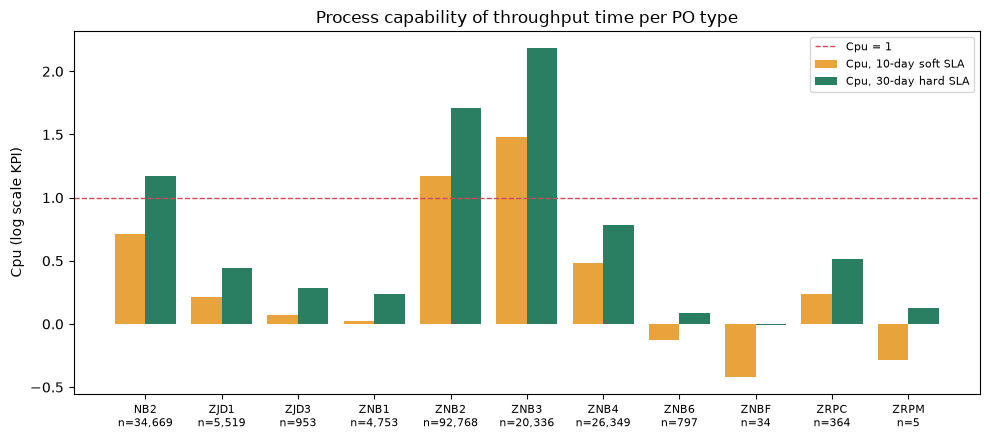

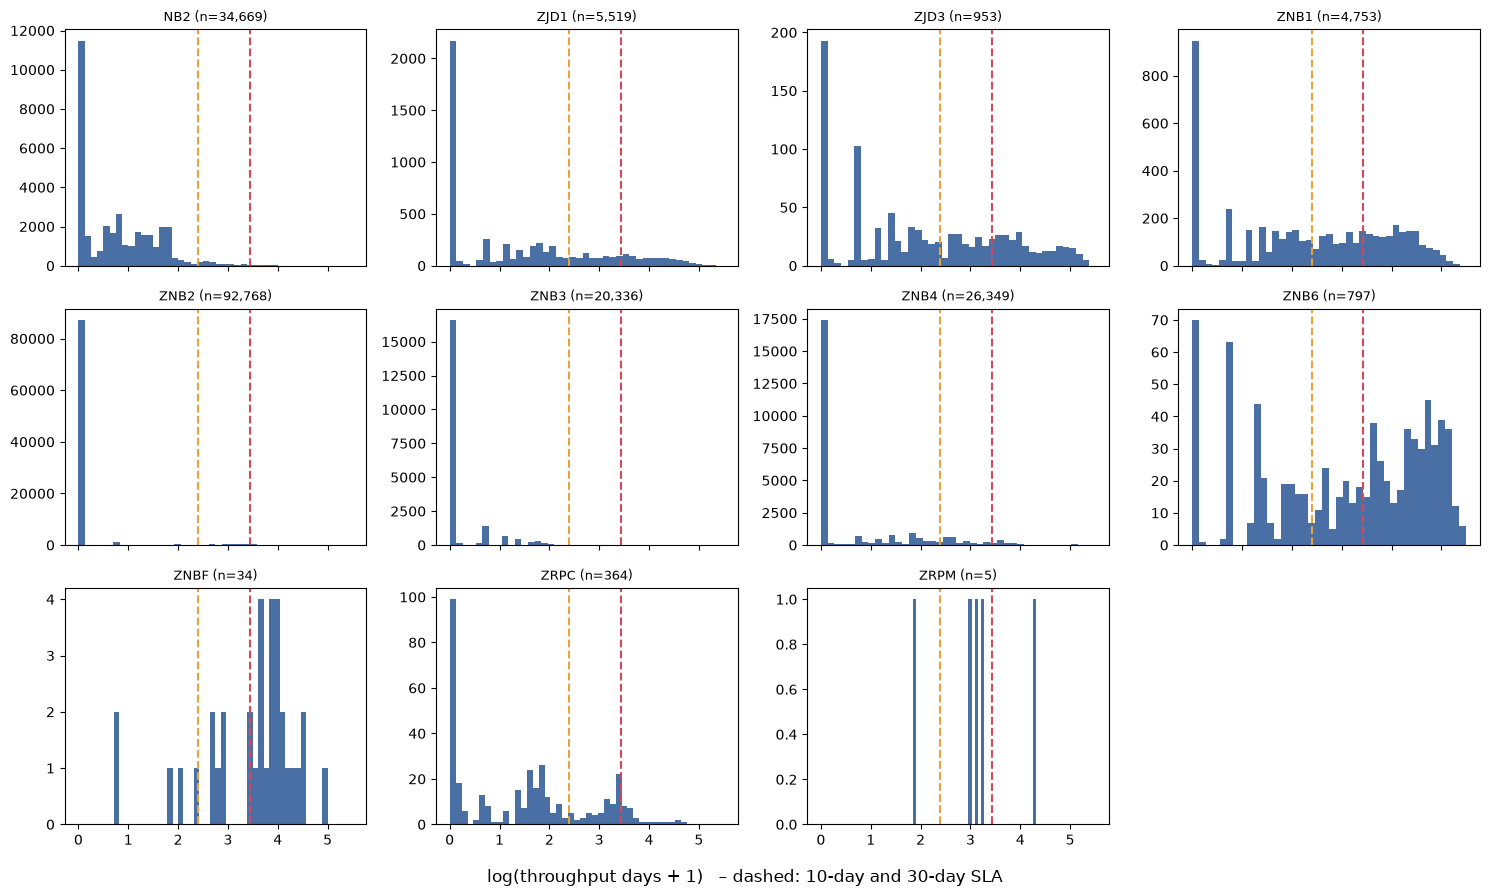

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
xs = np.arange(len(cap))
ax.bar(xs - 0.2, cap.Cpu_soft10, 0.4, label="Cpu, 10-day soft SLA", color="#e8a33d")
ax.bar(xs + 0.2, cap.Cpu_hard30, 0.4, label="Cpu, 30-day hard SLA", color="#2a7f62")
ax.axhline(1, color="#d1495b", ls="--", lw=1, label="Cpu = 1")
ax.set_xticks(xs, [f"{i}\nn={n:,}" for i, n in zip(cap.index, cap.cases)], fontsize=8)
ax.set_ylabel("Cpu (log scale KPI)")
ax.set_title("Process capability of throughput time per PO type")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "capability.png", dpi=130)
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(15, 9), sharex=True)
for ax, code in zip(axes.flat, PO_TYPES):
    y = cases.loc[cases.po_type == code, "log_throughput_days"]
    ax.hist(y, bins=40, color="#4a6fa5")
    for d, col in ((SLA_SOFT_DAYS, "#e8a33d"), (SLA_HARD_DAYS, "#d1495b")):
        ax.axvline(np.log(d + 1), color=col, ls="--")
    ax.set_title(f"{code} (n={len(y):,})", fontsize=9)
axes.flat[-1].axis("off")
fig.supxlabel("log(throughput days + 1)   – dashed: 10-day and 30-day SLA")
fig.tight_layout()
fig.savefig(FIG / "throughput_distributions.png", dpi=110)
plt.show()

### When does an invoice meet the SLA? Three end points

The log ends at posting, not at payment, so "met the SLA" depends on where the clock stops:

1. **Case, first to last event** – includes rework after posting (reversals, re-postings).
2. **Case, first event to first posting** – when the PO first became payable.
3. **Invoice cycle, first event to first posting** – each `SAP_PO_No` gets its own clock.

In [19]:
def sigma_within(c, col):
    """Within-subgroup sigma, estimated the same way as in the control charts."""
    c = c.dropna(subset=[col]).sort_values("start")
    weeks = c.groupby("start_week")[col]
    if len(c) / max(weeks.ngroups, 1) >= MIN_CASES_PER_WEEK:
        agg = weeks.agg(["std", "size"])
        agg = agg[agg["size"] >= MIN_SUBGROUP]
        return np.sqrt(((agg["size"] - 1) * agg["std"] ** 2).sum() / (agg["size"] - 1).sum())
    return np.abs(np.diff(c[col].values)).mean() / 1.128


def posting_capability(units):
    """Cpu and breach rates for time-to-first-posting; `units` are cases or invoice cycles."""
    out = []
    for code, name in PO_TYPES.items():
        c = units[(units.po_type == code) & units.posted]
        y = c.log_time_to_post_days
        mu, s_w = y.mean(), sigma_within(c, "log_time_to_post_days")
        r = {"po_type": code, "posted": len(c), "not_posted": int(((units.po_type == code) & ~units.posted).sum()),
             "mean_log_ttp": mu, "sigma_within": s_w, "median_ttp_days": c.time_to_post_days.median()}
        for tag, usl_days in (("soft10", SLA_SOFT_DAYS), ("hard30", SLA_HARD_DAYS)):
            usl = np.log(usl_days + 1)
            r[f"Cpu_{tag}"] = (usl - mu) / (3 * s_w)
            r[f"observed_breach_{tag}"] = (c.time_to_post_days > usl_days).mean()
            r[f"cases_breach_{tag}"] = int((c.time_to_post_days > usl_days).sum())
        out.append(r)
    return pd.DataFrame(out).set_index("po_type")


cap_post = posting_capability(cases)
cap_post["reposted_cases"] = cases[cases.posted].groupby("po_type").n_postings.agg(lambda s: int((s > 1).sum()))
cap_post.to_csv(OUT / "capability_first_post.csv")
cap_inv = posting_capability(inv)
cap_inv.to_csv(OUT / "capability_invoice.csv")

pd.DataFrame({
    "Cpu10 last event": cap.Cpu_soft10, "Cpu10 first post": cap_post.Cpu_soft10, "Cpu10 per invoice": cap_inv.Cpu_soft10,
    "late>10d last event": cap.cases_breach_soft10, "late>10d first post": cap_post.cases_breach_soft10,
    "late>10d per invoice": cap_inv.cases_breach_soft10,
}).round(2)

,Cpu10 last event,Cpu10 first post,Cpu10 per invoice,late>10d last event,late>10d first post,late>10d per invoice
po_type,,,,,,
NB2,0.71,0.73,0.73,1201,1144,1118
ZJD1,0.21,0.47,0.33,1509,523,1672
ZJD3,0.07,0.40,0.20,400,117,572
ZNB1,0.02,0.34,0.23,2354,800,3071
ZNB2,1.17,1.60,2.12,3117,1636,1206
ZNB3,1.48,1.51,1.51,107,95,95
ZNB4,0.49,0.88,1.03,3576,830,685
ZNB6,-0.13,-0.11,-0.11,504,488,501
ZNBF,-0.42,-0.40,-0.38,29,29,34


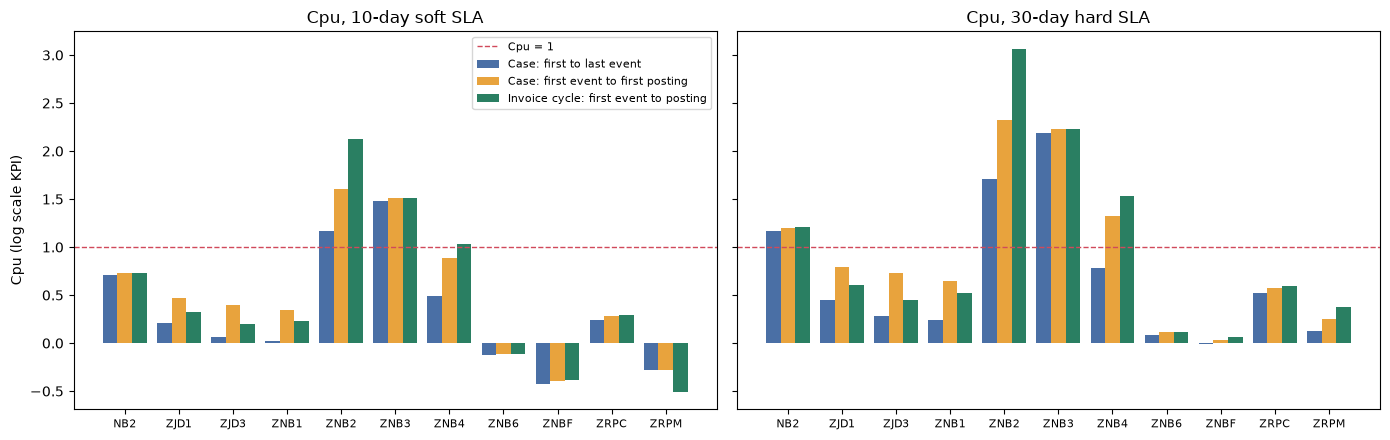

In [20]:
xs = np.arange(len(cap))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, tag, title in ((axes[0], "soft10", "10-day soft SLA"), (axes[1], "hard30", "30-day hard SLA")):
    ax.bar(xs - 0.27, cap[f"Cpu_{tag}"], 0.27, label="Case: first to last event", color="#4a6fa5")
    ax.bar(xs, cap_post[f"Cpu_{tag}"], 0.27, label="Case: first event to first posting", color="#e8a33d")
    ax.bar(xs + 0.27, cap_inv[f"Cpu_{tag}"], 0.27, label="Invoice cycle: first event to posting", color="#2a7f62")
    ax.axhline(1, color="#d1495b", ls="--", lw=1, label="Cpu = 1")
    ax.set_xticks(xs, cap.index, fontsize=8)
    ax.set_title(f"Cpu, {title}")
axes[0].set_ylabel("Cpu (log scale KPI)")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "capability_end_points.png", dpi=130)
plt.show()

## 4. Prioritisation

One table per PO type combining volume, manual work, rework, SLA risk and capability.

- **Rework** = an activity repeated *within the same invoice cycle* (repeats across cycles are just more invoices).
- **discount_at_risk_nok** is an upper bound: 2% of the invoice value of cases over 10 days, assuming every invoice had 2%/10-day terms.

In [21]:
act = df.groupby(["PO_ID", "Activity_ID"]).size().unstack(fill_value=0)
act_cycle = df.groupby(["PO_ID", "SAP_PO_No", "Activity_ID"]).size()
cases["has_rework"] = (act_cycle > 1).groupby(level="PO_ID").any()
cases["invoice_cycles"] = cyc
cases["auto_post_failed"] = act.get("Auto posting failed", 0) > 0
cases["approval"] = act.get("Sent for approval", 0) > 0
cases["deleted"] = act.get("Invoice document deleted", 0) > 0
cases["touchless"] = cases.manual_count == 0
cases["breach10"] = cases.throughput_days > SLA_SOFT_DAYS
cases["breach30"] = cases.throughput_days > SLA_HARD_DAYS

g = cases.groupby("po_type")
p = pd.DataFrame({
    "name": pd.Series(PO_TYPES),
    "cases": g.size(),
    "touchless_rate": g.touchless.mean(),
    "mean_manual": g.manual_count.mean(),
    "total_manual": g.manual_count.sum(),
    "median_tp_days": g.throughput_days.median(),
    "rework_rate": g.has_rework.mean(),
    "mean_invoice_cycles": g.invoice_cycles.mean(),
    "auto_post_failed_rate": g.auto_post_failed.mean(),
    "approval_rate": g.approval.mean(),
    "deleted_rate": g.deleted.mean(),
    "breach10_rate": g.breach10.mean(),
    "breach30_rate": g.breach30.mean(),
    "breach10_cases": g.breach10.sum(),
    "discount_at_risk_nok": cases[cases.breach10].groupby("po_type").invoice_value_nok.sum() * 0.02,
})
p["case_share"] = p.cases / p.cases.sum()
p["manual_share"] = p.total_manual / p.total_manual.sum()
p["late_invoices_10d"] = cap_inv.cases_breach_soft10
p["Cpu10_invoice"] = cap_inv.Cpu_soft10
p["kpis_in_control"] = control.groupby("po_type").in_control.sum().astype(int)
p = p.sort_values("cases", ascending=False)
p.index.name = "po_type"
p.to_csv(OUT / "priority.csv")
print(f"total discount at risk: {p.discount_at_risk_nok.sum():,.0f} NOK")
p.drop(columns="name").round(3)

total discount at risk: 175,833,242 NOK


,cases,touchless_rate,mean_manual,total_manual,median_tp_days,rework_rate,mean_invoice_cycles,auto_post_failed_rate,approval_rate,deleted_rate,breach10_rate,breach30_rate,breach10_cases,discount_at_risk_nok,case_share,manual_share,late_invoices_10d,Cpu10_invoice,kpis_in_control
po_type,,,,,,,,,,,,,,,,,,,
ZNB2,92768,0.962,0.057,5309,0.003,0.002,1.049,0.022,0.000,0.014,0.034,0.012,3117,3.590455e+05,0.497,0.112,1206,2.123,0
NB2,34669,0.660,0.542,18807,1.014,0.242,1.014,0.082,0.020,0.005,0.035,0.005,1201,1.080254e+05,0.186,0.397,1118,0.733,0
ZNB4,26349,0.934,0.097,2569,0.003,0.007,1.283,0.023,0.002,0.024,0.136,0.044,3576,2.228408e+06,0.141,0.054,685,1.034,0
ZNB3,20336,0.951,0.059,1204,0.002,0.003,1.020,0.002,0.006,0.001,0.005,0.001,107,1.371765e+04,0.109,0.025,95,1.510,0
ZJD1,5519,0.598,1.123,6200,2.053,0.044,1.877,0.015,0.054,0.029,0.273,0.151,1509,8.144449e+07,0.030,0.131,1672,0.326,0
ZNB1,4753,0.475,1.954,9289,9.348,0.060,2.898,0.014,0.052,0.052,0.495,0.307,2354,8.402953e+07,0.025,0.196,3071,0.231,0
ZJD3,953,0.526,1.720,1639,6.010,0.095,2.782,0.035,0.065,0.050,0.420,0.255,400,7.373728e+06,0.005,0.035,572,0.197,0
ZNB6,797,0.267,2.292,1827,29.099,0.350,1.102,0.009,0.040,0.016,0.632,0.498,504,1.572157e+05,0.004,0.039,501,-0.109,0
ZRPC,364,0.261,1.027,374,4.019,0.140,1.159,0.022,0.008,0.052,0.253,0.077,92,1.369872e+04,0.002,0.008,83,0.295,0


Monthly drift of the case population (explains many control-chart signals; the last months are thinner and slower):

In [22]:
monthly = cases.groupby(cases.start.dt.to_period("M")).agg(
    cases=("touchless", "size"), touchless=("touchless", "mean"),
    breach10=("breach10", "mean"), completed=("completed", "mean"))
monthly.round(3)

,cases,touchless,breach10,completed
start,,,,
2025-07,47513,0.892,0.048,0.992
2025-08,59696,0.883,0.051,0.995
2025-09,61418,0.862,0.088,0.985
2025-10,14413,0.831,0.097,0.991
2025-11,3507,0.685,0.212,0.982


### Conclusions (from the report)

- **ZNB1 (manual order) and ZJD1 (normal order): time to posting.** Together they hold about 94% of the discount at risk;
  per invoice their 10-day Cpu is far below 1, and manual posting is the slow route.
- **NB2 (return to vendor): manual work.** Returns are "reverse POs" that follow an earlier purchase. A large share of all manual activities, and about a quarter of its cases have
  real rework within an invoice.
- **ZJD3 (automatic order):** per-invoice 10-day Cpu of only about 0.2, despite being "automatic".
- Almost no PO type is in statistical control on the strict X̄ charts; with thousands of cases per week the limits are very
  narrow, and the case mix drifts from September onwards.

See `output/report.html` in the project for the full write-up.